In [254]:
import gc
import sys
import time
from functools import partial
from pathlib import Path
from typing import Any

import arviz as az
import joblib
import numpy as np
import pandas as pd
import statsmodels.api as sm
import yaml
from sklearn import set_config
from sklearn.base import (
    BaseEstimator,
    OneToOneFeatureMixin,
    TransformerMixin,
    clone,
)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    get_scorer,
    make_scorer,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.utils.parallel import Parallel, delayed
from sklearn.utils.validation import check_is_fitted
from tqdm.auto import tqdm

sys.path.insert(0, str(Path.cwd().parent))

from utils.bart_article import BARTAtrRegressor
from utils.cache import cached, content_hash
from utils.fast_OLS import DiagnosticoOLS
from utils.geo import (
    LOCALITY_ALIASES,
    add_landmark_distances,
    classify_city,
    fill_locality,
    inside_bbox_mask,
    locality_price_outliers,
    snap_locality,
)
from utils.map_graph import create_map, show_map
from utils.mcmc_traceplot import extract_chains, plot_trace
from utils.mutual_inf_plot import (
    analizar_relevancia_caracteristicas,
    graficar_score_relevancia,
)
from utils.preprocessing import (
    FrequencyEncoder,
    NearestNeighborImputer,
    OutlierFilterRegressor,
    amenity_feature_names,
    amenity_features,
    clip_round,
    grouped_feature_name,
    impute_bimodal,
    log_feature_names,
    months_listed,
    months_listed_names,
)
from utils.shap_explanaitor import compute_shap, plot_shap, shap_report
from utils.triple_plot import normality_report

# Every step returns a DataFrame, so later steps can pick columns by name.
set_config(transform_output="pandas")

ROOT_DIR = Path.cwd().parent

DATA_DIR = ROOT_DIR / "data"

GEO_DIR = ROOT_DIR / "geodata"

CACHE_DIR = ROOT_DIR / "cv_cache"

# Editing these modules invalidates the cached fits and CV.
PIPELINE_SOURCES = [
    ROOT_DIR / "utils" / "preprocessing.py",
    ROOT_DIR / "utils" / "geo.py",
]

In [255]:
def acc_within_10(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Proporción de inmuebles estimados dentro del ±10% del valor real.

    Evalúa la precisión dentro del rango óptimo de negociación comercial.
    Un porcentaje mayor indica una alta densidad de estimaciones listas
    para cierre de negocio sin fricción de precio.
    """
    errores_pct = np.abs((y_pred - y_true) / y_true)
    return float(np.mean(errores_pct <= 0.10) * 100)


def acc_within_20(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Proporción de inmuebles estimados dentro del ±20% del valor real.

    Mide el cumplimiento de la banda máxima de tolerancia aceptable en AVM.
    Permite identificar qué porcentaje del portafolio se mantiene en un rango
    operativamente defendible antes de considerar la estimación como errónea.
    """
    errores_pct = np.abs((y_pred - y_true) / y_true)
    return float(np.mean(errores_pct <= 0.20) * 100)


def sobreprediccion_rate(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Porcentaje de inmuebles donde la predicción supera el valor real
    (y_pred > y_true).

    Cuantifica el riesgo de sobreprecio en el mercado. Un porcentaje elevado
    (>50%) indica sesgo positivo, lo que incrementa el riesgo de estancar los
    inmuebles en portales inmobiliarios al superar la disposición a pagar.
    """
    return float(np.mean(y_pred > y_true) * 100)


# --- Diccionario de Scorers Completo para CV ---
METRICAS_CV = {
    # Métricas estándar de sklearn (se minimizan, requieren neg_)
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "MAPE": "neg_mean_absolute_percentage_error",
    "R2": "r2",
    # Métricas comerciales (se maximizan / monitorean directamente)
    "Acc_10": make_scorer(acc_within_10, greater_is_better=True),
    "Acc_20": make_scorer(acc_within_20, greater_is_better=True),
    "Sobreprediccion": make_scorer(
        sobreprediccion_rate, greater_is_better=False
    ),
}

In [256]:
## load yamls
bogota_marks_yaml_path = GEO_DIR / "bogota_landmarks.yaml"
with open(bogota_marks_yaml_path, "r", encoding="utf-8") as file:
    geo_data = yaml.safe_load(file)

In [257]:
positive_landmarks = geo_data.get("positive_landmarks", {})
negative_landmarks = geo_data.get("negative_landmarks", {})

# Implementación de BART basado en Cao et al. (2024)

En este cuaderno se adapta la metodología de recortes adaptativos (*adaptive trimming*) desarrollada por **Cao et al. (2024)** para modelos BART (*Bayesian Additive Regression Trees*), la cual permite identificar y filtrar iterativamente las observaciones anómalas o atípicas (*outliers*) de la muestra sin perder rigurosidad en la estimación. Adicionalmente, se compara el desempeño predictivo de esta propuesta frente a las metodologías econométricas y de aprendizaje automático consolidadas en la literatura de avalúos masivos.

El cuaderno recupera las fases de limpieza y depuración previas y las integra dentro de una *pipeline* de *Machine Learning* que implementa la partición estándar y la validación cruzada (*Cross-Validation*), siguiendo el esquema de evaluación fuera de muestra (*out-of-sample*) planteado por **Lozano-Gracia y Anselin (2012)**. De acuerdo con los hallazgos de estos mismos autores para Bogotá, se sustituye la recolección presencial y costosa de zonas homogéneas por la extracción automatizada de variables geodésicas calculadas mediante Sistemas de Información Geográfica (SIG), estructurando tres nuevas columnas de distancia espacial:

1. **Distancia a la estación de TransMilenio más cercana**: Variable que mide la accesibilidad al sistema de transporte masivo, un atributo clave que condiciona la disposición a pagar de los hogares y la estructuración del valor del suelo según la revisión teórica realizada por **Chang (2006)**.
2. **Distancia al** **landmark** **'positivo' más cercano**: Atributo que capta la revalorizacion generada por amenidades urbanas y espacios públicos. Al respecto, **Villada-Medina et al. (2023)** demuestran empíricamente en el contexto colombiano la valorización directa que ejercen los centros comerciales en el precio de la vivienda (con incrementos de entre 3.59% y 7.39% en radios de influencia de 0.5 km), mientras que **Loret de Mola et al. (2017)** resaltan la alta prioridad económica que los compradores de megaciudades latinoamericanas otorgan a la presencia de parques y áreas verdes metropolitanas.
3. **Distancia al** **landmark** **'negativo' más cercano**: Variable diseñada para registrar la penalización sobre el precio por metro cuadrado ocasionada por la proximidad a desamenidades o sectores de deterioro urbano (tales como la Cárcel La Modelo, El Bronx o San Bernardo). Esta aproximación se ampara en los desarrollos de **Tapia et al. (2025)** e **Iban (2022)**, quienes integran explícitamente en sus modelos de valuación masiva las distancias a penitenciarías, zonas industriales y depósitos de desechos para capturar el descuento comercial asociado a estas externalidades negativas.

# Recuperar el df original.

En esta seccion  se retoma el mismo df que se tuvo inicialmente, se recuperan las elimiaciones de atipicos y de calidad general realizados en `notebooks/data_cleaning.ipynb` y dentro de un pipeline basado en `notenooks/data_preparation.ipynb` se agregan las nuevas distancias a landmarks planteadas, adicionalmente de esta seccion se espera como resultado 2 df, uno con varias variables transformadas en log para el usar modelos como OLS y otro sin las varaibles escaladas o trasnformadas mas alla de una pipeline de inputacion y codificacion para los modelos de arbol como XGBoost o BART.

Se plantea usar como variable objetivo el precio del inmueble, para los modelos OLS tanto en arboles se utiliza el precio en log, y usando el objeto `TransformedTargetRegressor` para regresar a la unidad interpretable.

In [258]:
df = pd.read_csv(DATA_DIR / "fincaraiz_venta_bogota_20260803.csv")

In [259]:
sizes = {"Inicial": len(df)}

## Limpieza previa al pipeline

Antes del pipeline solo se hace lo que no aprende nada de los datos: quitar
columnas sin uso, restringir la base a la población de estudio y corregir los
registros inconsistentes de `notebooks/data_cleaning.ipynb`. Como ninguno de
estos pasos estima un parámetro, aplicarlos a toda la base antes de la partición
no filtra información del conjunto de prueba. Además, varios eliminan filas, y
un paso de sklearn no puede hacerlo.

Lo que sí se estima con los datos (imputación, umbrales IQR, codificación) queda
dentro del pipeline, para que se reaprenda en cada *fold* de la validación
cruzada.

### Columnas sin uso y moneda

Se eliminan los identificadores, la URL, la dirección y `total_monthly_cost`.
Un único inmueble está cotizado en `U$S` y casi vacío; al quitarlo,
`price_currency` queda constante y también se elimina.

In [260]:
df = df.drop(
    columns=[
        "listing_id",
        "operation",
        "source_url",
        "total_monthly_cost",
        "address_text",
    ]
)
df = df[df["price_currency"] != "U$S"].drop(columns="price_currency")
sizes["Moneda COP"] = len(df)

### Solo vivienda

El análisis se limita a uso residencial, así que se descartan los inmuebles
comerciales. `cabana` también sale: tiene un solo registro.

In [261]:
residential = [
    "casa",
    "apartamento",
    "apartaestudio",
    "casa_campestre",
    "habitacion",
    "finca",
]
df = df[df["property_type"].isin(residential)]
sizes["Vivienda"] = len(df)

### Variables discretas inconsistentes

- `bedrooms`: −1 y 0 no son cantidades válidas, se vuelven `NaN`.
- `bathrooms`: 0 se vuelve `NaN`.
- `parking_spaces`: −1 y −2 se corrigen a 1 y 2.
- `floor`: valores como 101, 301 o 502 se dividen entre 100 y se redondean.
- `stratum`: debe estar entre 1 y 6; valores como 110 no permiten saber el
  estrato real, así que esas filas se eliminan.

In [262]:
df["bedrooms"] = df["bedrooms"].replace([-1, 0], np.nan)
df["bathrooms"] = df["bathrooms"].replace(0, np.nan)
df["parking_spaces"] = df["parking_spaces"].replace({-1: 1, -2: 2})
df["floor"] = df["floor"].where(
    df["floor"] <= 100, (df["floor"] / 100).round()
)
df = df[~(df["stratum"] > 6)]  # NaN strata are kept for imputation
sizes["Estrato válido"] = len(df)

### Rango de precios del estudio

Se conservan los precios entre \$30 millones y \$20.000 millones. Por debajo
hay precios de 0 o 1 peso y cifras que parecen arriendos; por encima solo hay
errores de digitación. El inmueble legítimo más caro cuesta \$12.000 millones y
el siguiente precio publicado ya es de \$269.000 millones: cinco inmuebles de
56 a 255 m² cotizados entre \$269.000 y \$860.000 millones, con tres ceros de
más (miles de millones por m², frente a una mediana de \$6 millones). No son
precios de venta reales, así que este rango define la población y se aplica
antes de la partición.

Si quedara dentro del pipeline, el filtro de atípicos los sacaría del
entrenamiento pero seguirían en los *folds* de prueba: un inmueble de 1 peso
basta para que el MAPE de un *fold* llegue a 200.000.

In [263]:
df = df[df["price_amount"].between(30_000_000, 20_000_000_000)]
sizes["Rango de precio"] = len(df)

### Atípicos de precio por localidad

Se eliminan los precios por fuera de 2.5 × IQR de su propia localidad, como en la
sección *Check coordinates quality* de `data_cleaning.ipynb`, con dos
correcciones:

1. **Nombres.** El sitio escribe "Usaquen", "Santafe", "Ciudad Bolivar" y los
   recuadros usan "Usaquén", "Santa Fe", "Ciudad Bolívar". En el cuaderno
   original la mitad de las localidades no coincidía y nunca se revisaba, entre
   ellas Usaquén, el mercado más grande. Ahora se normalizan con
   `LOCALITY_ALIASES`.
2. **Solo la localidad propia.** Los recuadros se superponen. Con los nombres
   ya corregidos, revisar cada punto contra todos los recuadros en los que cae
   hacía que los umbrales de Engativá eliminaran 1.591 inmuebles de Suba y
   Barrios Unidos, ninguno de Engativá. Cada fila se compara solo con los
   umbrales de su localidad, y solo si sus coordenadas caen en ese recuadro.

In [264]:
df["locality"] = df["locality"].replace(LOCALITY_ALIASES)
locality_outliers = locality_price_outliers(df, multiplier=2.5)
print(
    f"locality price outliers: {locality_outliers.sum()} "
    f"({locality_outliers.mean():.2%})"
)
df = df[~locality_outliers]
sizes["Atípicos por localidad"] = len(df)

locality price outliers: 558 (2.46%)


### Ciudad y localidad desde las coordenadas

`city` se reescribe a partir de la latitud y la longitud; los inmuebles por
fuera de Cundinamarca se eliminan. Las pocas ciudades que no caen en ningún
municipio quedan en `NaN` y se imputan en el pipeline.

`locality` se completa con el recuadro más pequeño que contiene el punto y luego
con el borde más cercano a menos de 0.02°. Las filas que siguen sin localidad
tienen coordenadas que no corresponden a Bogotá y se eliminan.

In [265]:
df["city"] = classify_city(df["latitude"], df["longitude"])
df = df[inside_bbox_mask(df["latitude"], df["longitude"])]
sizes["Dentro de Cundinamarca"] = len(df)

df["locality"] = snap_locality(
    fill_locality(df["locality"], df["latitude"], df["longitude"]),
    df["latitude"],
    df["longitude"],
)
df = df[df["locality"].notna()]
sizes["Localidad ubicable"] = len(df)

### Columnas descartadas en los cuadernos previos

| Columna | Motivo |
|---|---|
| `floors_total` | 71 % de faltantes; `floor` da información similar |
| `age_bracket_label` | Equivale 1 a 1 a `age_bracket_code` |
| `agency_name` | Sesgaría el modelo hacia quién vende y no hacia el inmueble |
| `updated_at` | No se usa |
| `price_per_m2` | Se calcula con el precio: dejarla filtraría la variable objetivo |

`area_private_m2` se conserva hasta la codificación, porque la usan MICE y las
reglas de negocio, y allí se elimina por VIF. `published_at` se convierte en
`meses_ofertado` dentro del pipeline.

In [266]:
df = df.drop(
    columns=[
        "floors_total",
        "age_bracket_label",
        "agency_name",
        "updated_at",
        "price_per_m2",
    ]
).reset_index(drop=True)

steps = pd.Series(sizes, name="Filas").to_frame()
steps["% del inicial"] = (100 * steps["Filas"] / sizes["Inicial"]).round(2)
steps

,Filas,% del inicial
Inicial,31252,100.00
Moneda COP,31251,100.00
Vivienda,22853,73.12
Estrato válido,22754,72.81
Rango de precio,22715,72.68
Atípicos por localidad,22157,70.90
Dentro de Cundinamarca,22141,70.85
Localidad ubicable,22139,70.84


Faltantes que le quedan al pipeline:

In [267]:
(
    df.isna()
    .mean()
    .mul(100)
    .round(2)
    .loc[lambda s: s > 0]
    .sort_values(ascending=False)
    .rename("% faltante")
)

floor                 44.16
admin_fee             34.50
parking_spaces        25.61
area_private_m2       21.60
area_built_m2         15.60
amenities              7.86
construction_state     4.47
publisher_type         4.38
age_bracket_code       2.48
stratum                2.20
bedrooms               0.69
bathrooms              0.53
neighborhood           0.03
Name: % faltante, dtype: float64

## Crear variables de distancia a landmarks

In [268]:
df_pos = pd.DataFrame.from_dict(positive_landmarks, orient="index").assign(
    label="positive"
)
df_neg = pd.DataFrame.from_dict(negative_landmarks, orient="index").assign(
    label="negative"
)
df_landmarks = pd.concat([df_pos, df_neg])
df_landmarks = df_landmarks.reset_index().rename(
    columns={"index": "landmark_name"}
)

In [269]:
show_map(
    create_map(
        df_landmarks,
        name_col="landmark_name",
        label_col="label",
        colors={"positive": "green", "negative": "red"},
        cluster=False,
    )
)

In [270]:
df = add_landmark_distances(df_houses=df, df_landmarks=df_landmarks)

In [271]:
df

,property_type,price_amount,admin_fee,area_built_m2,area_private_m2,bedrooms,bathrooms,parking_spaces,stratum,floor,...,city,locality,neighborhood,latitude,longitude,amenities,publisher_type,published_at,dist_nearest_positive_km,dist_nearest_negative_km
0,casa,8.800000e+08,736000.0,160.0,151.0,3.0,3.0,2.0,4.0,NaN,...,Bogotá,Suba,UB. Hacienda Cordoba Niza,4.711642,-74.062946,Alarma|Baño Auxiliar|Calentador|Canchas Deport...,NaN,2023-01-24,1.277884,3.573925
1,casa,6.500000e+08,NaN,153.4,153.4,4.0,2.0,1.0,3.0,NaN,...,Bogotá,Barrios Unidos,Benjamin Herrera,4.655459,-74.073723,Baño Auxiliar|Colegios / Universidades|Estudio...,NaN,2023-01-31,2.026489,0.860543
2,casa,6.250000e+08,643500.0,120.0,120.0,4.0,3.0,2.0,5.0,1.0,...,Bogotá,Usaquén,Lagos DE Torca,4.764007,-74.042742,Baño Auxiliar|Calentador|Cancha de Tennis|Canc...,NaN,2023-02-08,0.452378,2.303056
3,apartamento,4.700000e+08,560000.0,56.0,58.0,1.0,2.0,1.0,4.0,2.0,...,Bogotá,Usaquén,Cedritos,4.721554,-74.036146,Ascensor|Barra estilo americano|Baño Auxiliar|...,NaN,2023-03-01,0.873108,1.940358
4,casa,3.300000e+09,NaN,NaN,350.0,4.0,3.0,2.0,6.0,2.0,...,Bogotá,Suba,San Jose DE Bavaria,4.769128,-74.061616,Balcón|Barra estilo americano|Baño Auxiliar|Ch...,inmobiliaria,2023-03-22,1.853694,2.562023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22134,casa,5.799000e+08,NaN,NaN,192.0,6.0,3.0,1.0,3.0,NaN,...,Bogotá,Fontibón,Centro Fontibon,4.676469,-74.136465,Alcantarillado|Baño Auxiliar|Cerca centro come...,inmobiliaria,2023-10-12,0.919885,0.240636
22135,casa,6.000000e+08,NaN,NaN,126.0,5.0,3.0,1.0,3.0,NaN,...,Bogotá,Engativá,Lujan,4.682503,-74.099924,Cerca a sector comercial|Cerca centro comercia...,inmobiliaria,2023-10-12,1.612638,2.898134
22136,apartamento,6.500000e+08,NaN,NaN,90.0,3.0,3.0,1.0,4.0,NaN,...,Bogotá,Teusaquillo,EL Recuerdo,4.628558,-74.083638,Ascensor|Baño Auxiliar|Calentador|Cerca a sect...,inmobiliaria,2023-11-02,1.202839,1.508250
22137,apartamento,1.870000e+08,NaN,NaN,41.0,2.0,1.0,NaN,2.0,NaN,...,Bogotá,Suba,Pinar DE Suba,4.755939,-74.078061,NaN,inmobiliaria,2023-11-03,1.611158,3.235970


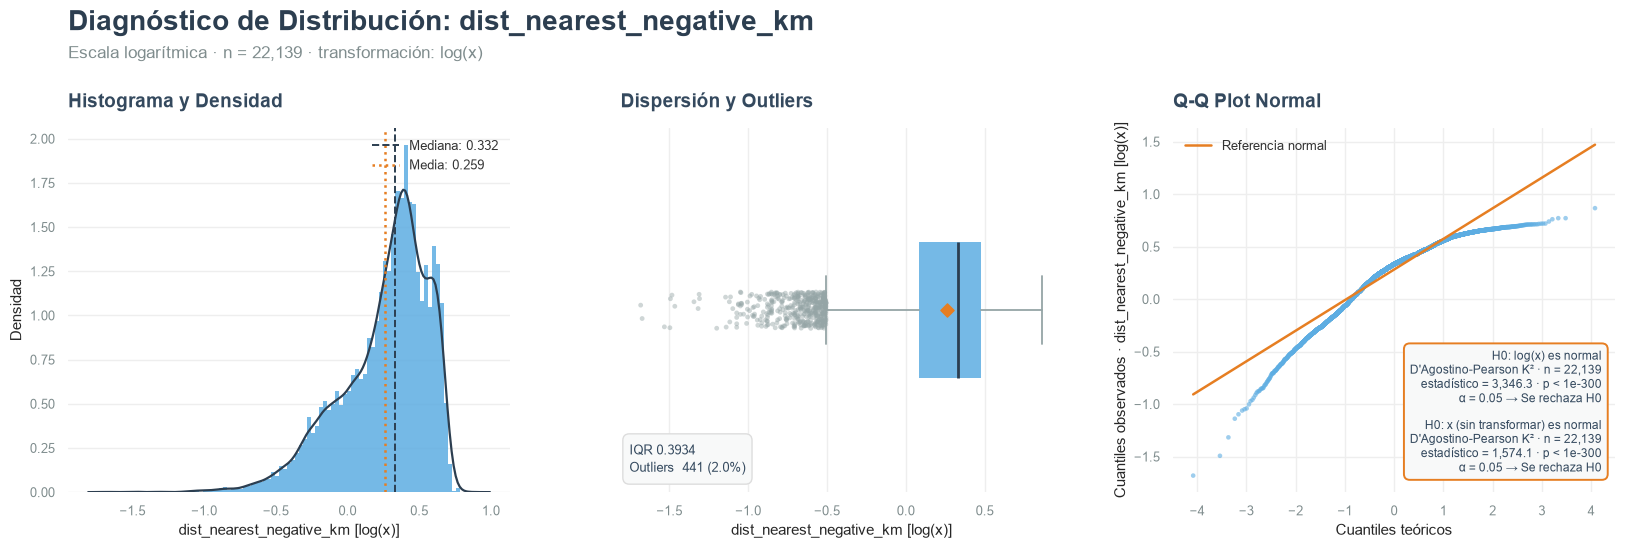

In [272]:
norm_pos = normality_report(
    df, "dist_nearest_negative_km", log_transformation=True
)

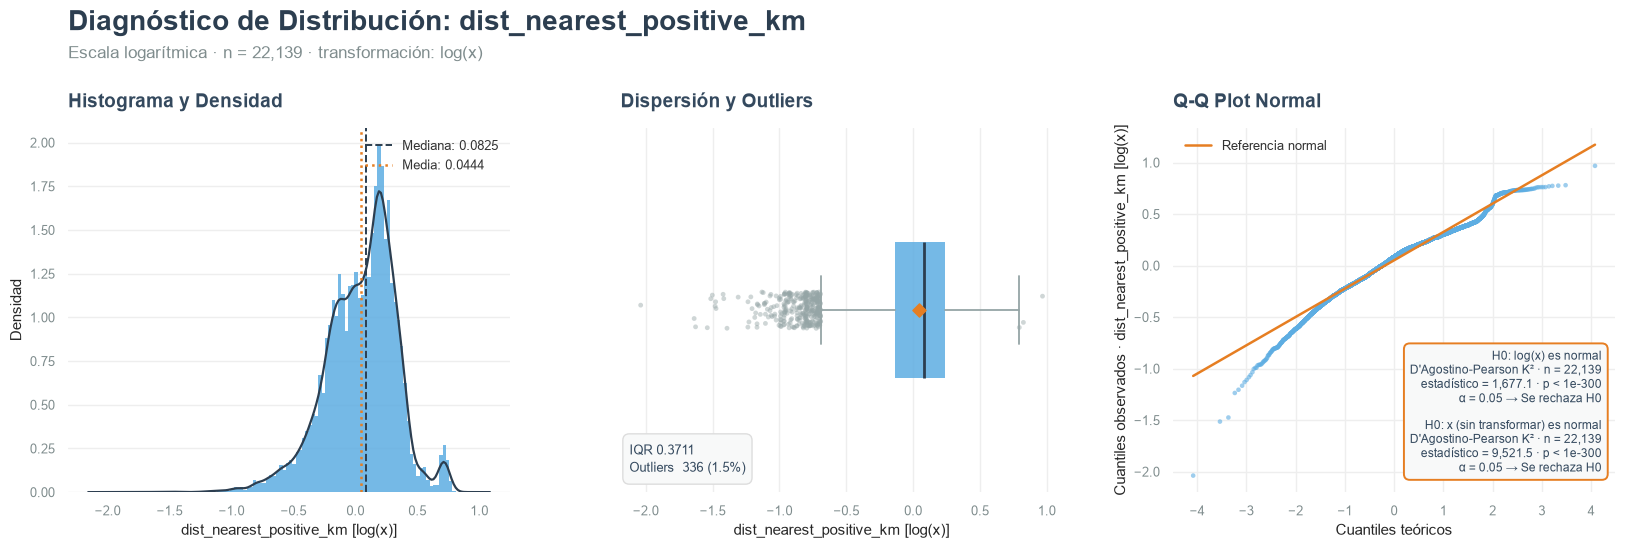

In [273]:
neg_pos = normality_report(
    df, "dist_nearest_positive_km", log_transformation=True
)

## Partición

La variable objetivo es `price_amount`, en pesos. El logaritmo se aplica dentro
del pipeline con `TransformedTargetRegressor`.


In [274]:
X = df.drop(columns="price_amount")
y = df["price_amount"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape

((17711, 21), (4428, 21))

In [275]:
X.head(3).T

,0,1,2
property_type,casa,casa,casa
admin_fee,736000.0,NaN,643500.0
area_built_m2,160.0,153.4,120.0
area_private_m2,151.0,153.4,120.0
bedrooms,3.0,4.0,4.0
bathrooms,3.0,2.0,3.0
parking_spaces,2.0,1.0,2.0
stratum,4.0,3.0,5.0
floor,NaN,NaN,1.0
age_bracket_code,4.0,5.0,4.0


## Pipeline

```
Pipeline
├── imputation                      (se ajusta con todas las filas de entrenamiento)
│   ├── simple    moda, bimodal, 1-NN, constantes
│   └── mice      IterativeImputer + ExtraTrees
└── outliers      OutlierFilterRegressor   ← elimina filas solo al ajustar
    └── TransformedTargetRegressor (log / exp)
        └── Pipeline
            ├── encoding    one-hot, frecuencia, meses_ofertado
            ├── amenities   banderas y conteo de amenidades
            └── model       DummyRegressor (provisional)
```

Un paso de sklearn debe devolver tantas filas como recibe, así que ningún
transformador puede eliminar atípicos. Por eso `OutlierFilterRegressor`
**envuelve** los pasos que vienen después de él. Al ajustar elimina las filas
atípicas de `X` y de `y` y entrena el resto solo con las filas que quedan. Al
predecir deja pasar todas las filas: un inmueble de prueba nunca se descarta,
simplemente el modelo no aprendió de los atípicos.

El `TransformedTargetRegressor` va dentro del filtro y no alrededor de él, para
que las reglas lean el precio en pesos, igual que en `data_cleaning.ipynb`.

### 1. Imputación

Se hace en dos etapas porque MICE, en `data_cleaning.ipynb`, se ajustó cuando
las imputaciones simples ya estaban hechas.

| Variable | Método | Origen |
|---|---|---|
| `city`, `construction_state`, `bedrooms`, `bathrooms` | Moda | < 5 % faltante, sin MAR |
| `age_bracket_code` | Bimodal 50/50 entre 16–30 y más de 30 años | ~5 %, sin MAR |
| `stratum` | Bimodal 50/50 entre 3 y 4 | sin MAR |
| `neighborhood` | 1-NN sobre latitud y longitud | |
| `amenities` | Constante "Ninguna" | no se imputa una combinación de amenidades |
| `publisher_type` | Constante "Particular" | faltante 1:1 con `agency_name`: venta directa |
| `admin_fee`, `area_*`, `parking_spaces`, `floor` | MICE (ExtraTrees) | MAR |

`construction_state` se imputaba con la moda dentro de cada rango de
antigüedad, pero "Usado" es la moda en todos los rangos, así que la moda global
da el mismo resultado.

MICE usa las mismas variables que en el cuaderno original, salvo
`log_price_amount` y `price_per_m2`: ambas se calculan con el precio, que no
está en `X`. `parking_spaces` y `floor` se redondean al final, porque MICE las
devuelve fraccionarias.

In [276]:
mice_numeric = [
    "stratum",
    "bedrooms",
    "bathrooms",
    "latitude",
    "longitude",
    "age_bracket_code",
    "parking_spaces",
    "admin_fee",
    "floor",
    "area_built_m2",
    "area_private_m2",
]
mice_categorical = ["property_type", "construction_state", "publisher_type"]
counts = ["parking_spaces", "floor"]

simple_imputation = ColumnTransformer(
    [
        (
            "mode",
            SimpleImputer(strategy="most_frequent"),
            ["city", "construction_state", "bedrooms", "bathrooms"],
        ),
        (
            "age_bimodal",
            FunctionTransformer(
                impute_bimodal,
                kw_args={"values": [5.0, 4.0]},
                feature_names_out="one-to-one",
            ),
            ["age_bracket_code"],
        ),
        (
            "stratum_bimodal",
            FunctionTransformer(
                impute_bimodal,
                kw_args={"values": [3.0, 4.0]},
                feature_names_out="one-to-one",
            ),
            ["stratum"],
        ),
        (
            "neighborhood_knn",
            NearestNeighborImputer(n_neighbors=1),
            ["neighborhood", "latitude", "longitude"],
        ),
        # The KNN branch consumes the coordinates but returns only the
        # neighbourhood, so they are passed through explicitly.
        ("coordinates", "passthrough", ["latitude", "longitude"]),
        (
            "no_amenities",
            SimpleImputer(strategy="constant", fill_value="Ninguna"),
            ["amenities"],
        ),
        (
            "direct_sale",
            SimpleImputer(strategy="constant", fill_value="Particular"),
            ["publisher_type"],
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

mice = Pipeline(
    [
        (
            "dummies",
            ColumnTransformer(
                [
                    (
                        "one_hot",
                        OneHotEncoder(
                            drop="first",
                            sparse_output=False,
                            handle_unknown="ignore",
                        ),
                        mice_categorical,
                    )
                ],
                remainder="passthrough",
                verbose_feature_names_out=False,
            ),
        ),
        (
            "iterative",
            IterativeImputer(
                estimator=ExtraTreesRegressor(
                    n_estimators=50, random_state=42, n_jobs=-1
                ),
                max_iter=10,
                random_state=42,
                initial_strategy="median",
                # Only the 5 columns with NaN get a model. The 22
                # complete ones never fill a value, and fitting them
                # made a fitted pipeline ~5x bigger (~14 GB vs 2.6).
                skip_complete=True,
            ),
        ),
        (
            "numeric_only",
            ColumnTransformer(
                [
                    (
                        "counts",
                        FunctionTransformer(
                            clip_round, feature_names_out="one-to-one"
                        ),
                        counts,
                    ),
                    (
                        "rest",
                        "passthrough",
                        [c for c in mice_numeric if c not in counts],
                    ),
                ],
                remainder="drop",  # the dummies were only MICE predictors
                verbose_feature_names_out=False,
            ),
        ),
    ]
)

mice_imputation = ColumnTransformer(
    [
        ("mice", mice, mice_numeric + mice_categorical),
        # Still needed downstream, for the encoding step.
        ("categorical", "passthrough", mice_categorical),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

imputation = Pipeline(
    [("simple", simple_imputation), ("mice", mice_imputation)]
)

### 2. Atípicos: reglas de negocio e IQR

En el orden de `data_cleaning.ipynb`:

1. **Reglas de negocio**: áreas construida y privada entre 10 y 5.000 m²
   (extremos excluidos). La regla de precio ya se aplicó antes del pipeline,
   como rango del estudio.
2. **IQR**: con las filas que pasan las reglas se calculan los umbrales de
   3 × IQR de precio, administración, precio por m² y ambas áreas. Se usa 3 y
   no 1.5 para no descartar inmuebles de lujo legítimos.

`price_per_m2` se reconstruye dentro del filtro como precio / área construida:
el filtro la usa como criterio, pero el modelo nunca la ve.

In [277]:
business_rules = {
    "area_built_m2": (10, 5_000, "neither"),
    "area_private_m2": (10, 5_000, "neither"),
}
iqr_columns = [
    "price_amount",
    "admin_fee",
    "price_per_m2",
    "area_built_m2",
    "area_private_m2",
]
ratio_columns = {"price_per_m2": ("price_amount", "area_built_m2")}

### 3. Codificación

Las codificaciones de `data_preparation.ipynb`:

| Variable | Codificación | Categoría base |
|---|---|---|
| `construction_state` | One-hot de las 4 más comunes + "Otros" | Usado |
| `city` | One-hot | Bogotá |
| `publisher_type` | One-hot | Particular |
| `property_type` | One-hot, sin agrupar | apartamento |
| `locality` | Frecuencia | |
| `neighborhood` | Frecuencia de los 20 barrios más comunes + "Otros" | |
| `published_at` | `meses_ofertado`: meses hasta agosto de 2026 | |
| `area_private_m2` | Se elimina (VIF) | |

Las frecuencias y las categorías se aprenden con el *fold* de entrenamiento.
`finca` (4 filas) o `habitacion` (7) pueden faltar en un *fold*, así que los
codificadores ignoran las categorías nuevas en lugar de fallar.

In [278]:
one_hot = {"sparse_output": False, "handle_unknown": "ignore"}

encoding = ColumnTransformer(
    [
        (
            "construction_state",
            OneHotEncoder(
                max_categories=5,  # the 4 most common + "Otros"
                drop=["Usado"],
                sparse_output=False,
                handle_unknown="infrequent_if_exist",
                feature_name_combiner=grouped_feature_name,
            ),
            ["construction_state"],
        ),
        ("city", OneHotEncoder(drop="first", **one_hot), ["city"]),
        (
            "publisher_type",
            OneHotEncoder(drop="first", **one_hot),
            ["publisher_type"],
        ),
        (
            "property_type",
            OneHotEncoder(drop=["apartamento"], **one_hot),
            ["property_type"],
        ),
        ("locality", FrequencyEncoder(), ["locality"]),
        (
            "neighborhood",
            FrequencyEncoder(top_n=20, suffix="_grouped_frec"),
            ["neighborhood"],
        ),
        (
            "months_listed",
            FunctionTransformer(
                months_listed,
                kw_args={"anchor": "2026-08"},
                feature_names_out=months_listed_names,
            ),
            ["published_at"],
        ),
        ("vif", "drop", ["area_private_m2"]),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

### 4. Amenidades

De la lista de amenidades se toman las dos más comunes como banderas
(`Trans Publico cerc`, `Zona Residencial`) y el número total de amenidades
(`n_amenities`, 0 cuando es "Ninguna"). La lista original se descarta.

In [279]:
amenities = ColumnTransformer(
    [
        (
            "amenities",
            FunctionTransformer(
                amenity_features, feature_names_out=amenity_feature_names
            ),
            ["amenities"],
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

### 5. Modelo (provisional)

`DummyRegressor` predice la mediana del log-precio. Solo ocupa el lugar del
modelo para poder ajustar y validar el pipeline completo; después se reemplaza
por `BARTAtrRegressor` de `utils/bart_article.py` o por cualquier otro
regresor.

In [280]:
placeholder = DummyRegressor(strategy="median")

### Ensamble

In [281]:
model = Pipeline(
    [
        ("imputation", imputation),
        (
            "outliers",
            OutlierFilterRegressor(
                TransformedTargetRegressor(
                    regressor=Pipeline(
                        [
                            ("encoding", encoding),
                            ("amenities", amenities),
                            ("model", placeholder),
                        ]
                    ),
                    func=np.log,
                    inverse_func=np.exp,
                ),
                bounds=business_rules,
                iqr_columns=iqr_columns,
                ratio_columns=ratio_columns,
                iqr_multiplier=3.0,
            ),
        ),
    ]
)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputation', ...), ('outliers', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simple', ...), ('mice', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using `

## Ajuste y verificación

El ajuste tarda unos dos minutos, casi todos en MICE. `fit_report` guarda en
`cv_cache/` lo que las celdas siguientes necesitan (umbrales, variables y
predicciones), no el modelo ajustado: con los ExtraTrees de MICE ese archivo
pesaría varios GB. Solo se vuelve a ajustar si cambian los datos, el pipeline,
la función o `utils/preprocessing.py` y `utils/geo.py`; `force_rerun=True`
obliga a recalcular.

In [282]:
@cached(cache_dir=CACHE_DIR, watch=PIPELINE_SOURCES)
def fit_report(pipeline, X_train, y_train, X_test):  # noqa: N803
    """Fit a clone of ``pipeline`` and keep only what the checks need.

    The fitted pipeline itself is not returned: MICE's fitted ExtraTrees
    would make the pickle gigabytes.
    """
    fitted = clone(pipeline).fit(X_train, y_train)
    outlier_filter = fitted.named_steps["outliers"]
    imputed = fitted.named_steps["imputation"].transform(X_train)
    features = outlier_filter.regressor_.regressor_[:-1].transform(
        imputed.iloc[outlier_filter.kept_]
    )
    return {
        "n_dropped_business": outlier_filter.n_dropped_business_,
        "n_dropped_iqr": outlier_filter.n_dropped_iqr_,
        "kept": outlier_filter.kept_,
        "fences": outlier_filter.fences_,
        "features": features,
        "y_pred": fitted.predict(X_test),
    }

In [283]:
report = fit_report(model, X_train, y_train, X_test)
print(
    f"business rules dropped {report['n_dropped_business']}, "
    f"IQR dropped {report['n_dropped_iqr']}; "
    f"kept {report['kept'].sum()} of {len(report['kept'])}"
)
report["fences"]

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\fit_report_09199495960d2b444e058a84c1aaceb7.pkl
business rules dropped 71, IQR dropped 1683; kept 15957 of 17711


,lower,upper
price_amount,-2.340000e+09,4.030000e+09
admin_fee,-2.201032e+06,3.505774e+06
price_per_m2,-5.413024e+06,1.758774e+07
area_built_m2,-4.980000e+02,8.110000e+02
area_private_m2,-4.880000e+02,7.930000e+02


Las variables con las que se entrena el modelo, sin faltantes:

In [284]:
features = report["features"]
print(
    f"{features.shape[1]} features, "
    f"{int(features.isna().sum().sum())} missing values"
)
features.head()

32 features, 0 missing values


,Trans Publico cerc,Zona Residencial,n_amenities,construction_state_grouped_A estrenar,construction_state_grouped_Buen estado,construction_state_grouped_Excelente estado,construction_state_grouped_Otros,city_Chía,city_Soacha,city_Zipaquirá,...,stratum,bedrooms,bathrooms,latitude,longitude,age_bracket_code,admin_fee,area_built_m2,dist_nearest_positive_km,dist_nearest_negative_km
6306,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.0,8.0,7.0,4.569837,-74.097230,5.0,185108.60,277.0,1.378700,2.237852
16483,1,1,17,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,3.0,2.0,4.586188,-74.161307,3.0,156672.00,62.0,0.204364,2.077674
6899,1,1,27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.0,4.0,2.0,4.710989,-74.072092,5.0,270890.24,126.0,2.180747,2.558892
12064,1,1,13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6.0,4.0,5.0,4.710879,-74.025356,5.0,2470000.00,360.0,1.634736,3.383936
4824,1,1,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,3.0,2.0,4.656250,-74.155936,4.0,108000.00,61.0,1.919504,2.918910


In [285]:
features.columns, features.shape

(Index(['Trans Publico cerc', 'Zona Residencial', 'n_amenities',
        'construction_state_grouped_A estrenar',
        'construction_state_grouped_Buen estado',
        'construction_state_grouped_Excelente estado',
        'construction_state_grouped_Otros', 'city_Chía', 'city_Soacha',
        'city_Zipaquirá', 'publisher_type_desarrollador',
        'publisher_type_inmobiliaria', 'property_type_apartaestudio',
        'property_type_casa', 'property_type_casa_campestre',
        'property_type_finca', 'property_type_habitacion', 'locality_frec',
        'neighborhood_grouped_frec', 'meses_ofertado', 'parking_spaces',
        'floor', 'stratum', 'bedrooms', 'bathrooms', 'latitude', 'longitude',
        'age_bracket_code', 'admin_fee', 'area_built_m2',
        'dist_nearest_positive_km', 'dist_nearest_negative_km'],
       dtype='str'),
 (15957, 32))

## Ver importancia y asociacion preliminar de vars

In [286]:
# The target of the rows the model trained on, on the log scale it fits.
df_ver_imp = features.assign(
    log_price_amount=np.log(y_train.loc[features.index])
)

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\analizar_relevancia_caracteristicas_28be13c4e811afeaee3dc30609d21e7b.pkl


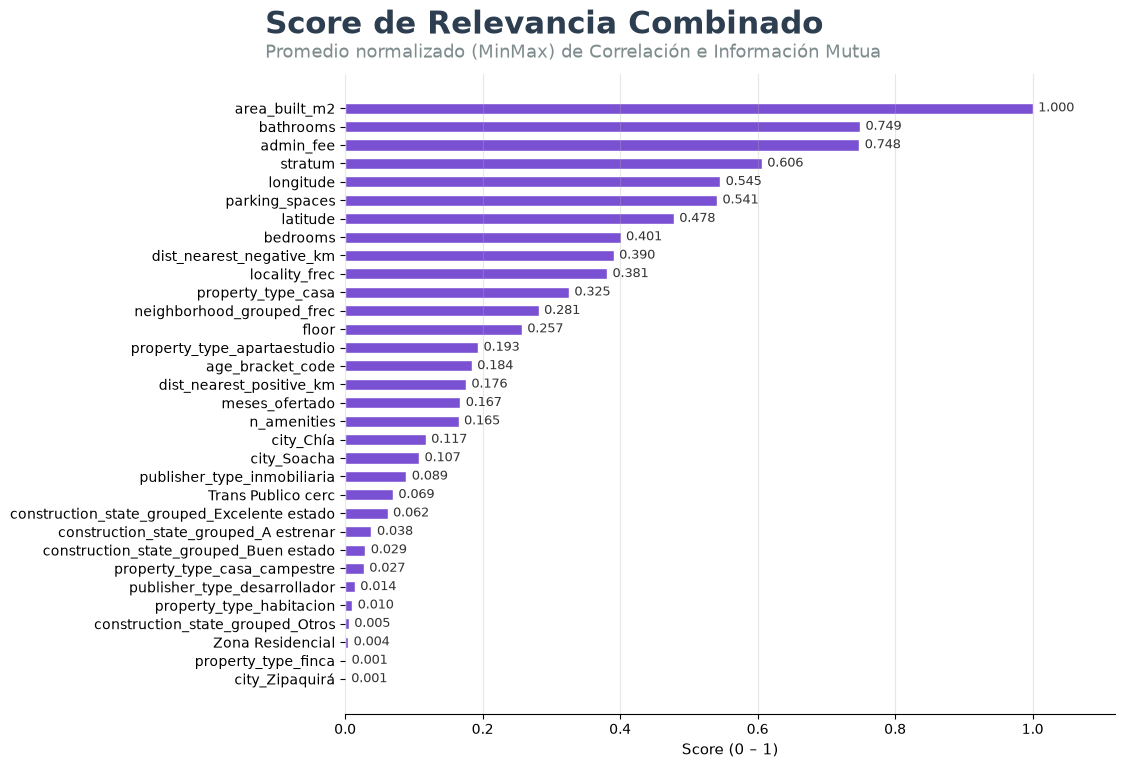

In [287]:
relevancia = cached(
    cache_dir=CACHE_DIR, watch=[ROOT_DIR / "utils" / "mutual_inf_plot.py"]
)(analizar_relevancia_caracteristicas)
df_score = relevancia(df_ver_imp, "log_price_amount", graficar=False)
fig, ax = graficar_score_relevancia(df_score)

Se plantea seleccionar con metodos embedidos con forward seleccionando 6 o 18 variables

In [288]:
ranking = df_score.sort_values("score", ascending=False)
ranking.insert(0, "rank", range(1, len(ranking) + 1))
ranking

,rank,correlacion,info_mutua,corr_scaled,mi_scaled,score
variable,,,,,,
area_built_m2,1,0.767273,0.963615,1.000000,1.000000,1.000000
bathrooms,2,0.700875,0.563135,0.913209,0.584398,0.748804
admin_fee,3,0.636460,0.642093,0.829011,0.666337,0.747674
stratum,4,0.653884,0.347024,0.851786,0.360127,0.605957
longitude,5,0.434312,0.506835,0.564778,0.525972,0.545375
parking_spaces,6,0.446914,0.482120,0.581251,0.500325,0.540788
latitude,7,0.303857,0.541211,0.394258,0.561646,0.477952
bedrooms,8,0.407382,0.261570,0.529578,0.271447,0.400512
dist_nearest_negative_km,9,0.334394,0.334171,0.434173,0.346789,0.390481


In [289]:
y_pred = report["y_pred"]
pd.Series(
    {
        "R2": r2_score(y_test, y_pred),
        "MAPE": mean_absolute_percentage_error(y_test, y_pred),
    }
)

R2     -0.114121
MAPE    0.713383
dtype: float64

## Facilitar la experimentacion

### Selección de variables por información mutua

`create_tree_selection_pipeline(model, n)` es `create_tree_pipeline` con un paso
`selection` entre `amenities` y `model`: un `SelectKBest` que conserva las `n`
variables con mayor información mutua con el log-precio. Como está dentro del
pipeline, se aprende en cada ajuste solo con las filas de entrenamiento que
dejan pasar los filtros de atípicos, ya imputadas y codificadas; en la
validación cruzada nunca ve el *fold* de prueba, así que no necesita una
validación interna propia.

Las variables elegidas se leen del pipeline ajustado con
`fitted["outliers"].regressor_.regressor_["selection"].get_feature_names_out()`.

In [290]:
def create_tree_pipeline(model, selection="passthrough"):
    return Pipeline(
        [
            ("imputation", clone(imputation)),
            (
                "outliers",
                OutlierFilterRegressor(
                    TransformedTargetRegressor(
                        regressor=Pipeline(
                            [
                                ("encoding", clone(encoding)),
                                ("amenities", clone(amenities)),
                                ("selection", selection),
                                ("model", clone(model)),
                            ]
                        ),
                        func=np.log,
                        inverse_func=np.exp,
                    ),
                    bounds=business_rules,
                    iqr_columns=iqr_columns,
                    ratio_columns=ratio_columns,
                    iqr_multiplier=3.0,
                ),
            ),
        ]
    )


def create_tree_selection_pipeline(model, n_features_to_select):
    """`create_tree_pipeline` that keeps the `n_features_to_select` features
    with the highest mutual information with the log-price."""
    return create_tree_pipeline(
        model,
        SelectKBest(
            # Fixed seed: the k-NN estimate of MI is random.
            partial(mutual_info_regression, random_state=42),
            k=n_features_to_select,
        ),
    )

In [291]:
log_columns = ["area_built_m2"]
log_transform = ColumnTransformer(
    [
        (
            "log",
            FunctionTransformer(np.log, feature_names_out=log_feature_names),
            log_columns,
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)


class ClipToTrainRange(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Clip every column to the range it had in the training rows.

    A linear model extrapolates without bound: a test listing with a typo
    such as ``admin_fee = 2_147_483_647`` gets a log-price in the hundreds,
    and ``np.exp`` turns it into infinity. Trees never predict outside
    their training range, so the tree pipelines do not need this step.
    """

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lower_ = X.min()
        self.upper_ = X.max()
        self.feature_names_in_ = X.columns.to_numpy(dtype=object)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self, "lower_")
        return pd.DataFrame(X).clip(self.lower_, self.upper_, axis=1)


def create_linear_pipeline(model, extra_steps=()):
    """Pipeline for linear models: log area, log price, optional steps.

    ``extra_steps`` go between the log transform and the model. Left
    empty, the pipeline is the same object the cached baseline was fitted
    with, so that cache stays valid.
    """
    steps = [
        ("encoding", clone(encoding)),
        ("amenities", clone(amenities)),
        ("log", clone(log_transform)),
        *extra_steps,
        ("model", clone(model)),
    ]
    return Pipeline(
        [
            ("imputation", clone(imputation)),
            (
                "outliers",
                OutlierFilterRegressor(
                    TransformedTargetRegressor(
                        regressor=Pipeline(steps),
                        func=np.log,
                        inverse_func=np.exp,
                    ),
                    bounds=business_rules,
                    iqr_columns=iqr_columns,
                    ratio_columns=ratio_columns,
                    iqr_multiplier=3.0,
                ),
            ),
        ]
    )


def create_linear_selection_pipeline(model, n_features_to_select):
    """`create_linear_pipeline` that logs the administration fee, clips each
    feature to its training range and keeps the `n_features_to_select`
    features with the highest mutual information with the log-price."""
    return create_linear_pipeline(
        model,
        [
            (
                "log_admin",
                ColumnTransformer(
                    [
                        (
                            "log",
                            FunctionTransformer(
                                np.log1p, feature_names_out=log_feature_names
                            ),
                            ["admin_fee"],
                        )
                    ],
                    remainder="passthrough",
                    verbose_feature_names_out=False,
                ),
            ),
            ("clip", ClipToTrainRange()),
            (
                "selection",
                SelectKBest(
                    # Fixed seed: the k-NN estimate of MI is random.
                    partial(mutual_info_regression, random_state=42),
                    k=n_features_to_select,
                ),
            ),
        ],
    )

In [292]:
linear_report = fit_report(
    create_linear_pipeline(DummyRegressor(strategy="median")),
    X_train,
    y_train,
    X_test,
)
linear_features = linear_report["features"]
linear_pred = linear_report["y_pred"]
print(
    f"{linear_features.shape[1]} features, "
    f"{int(linear_features.isna().sum().sum())} missing, "
    f"{int(np.isinf(linear_features).sum().sum())} infinite; "
    f"finite predictions: {np.isfinite(linear_pred).all()}"
)
linear_features[["log_area_built_m2"]].describe().T

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\fit_report_e14598bcd0f35584617e5099f0c3f1c5.pkl
32 features, 0 missing, 0 infinite; finite predictions: True


,count,mean,std,min,25%,50%,75%,max
log_area_built_m2,15957.0,4.77569,0.823083,2.694627,4.110874,4.770685,5.438079,6.684612


# Guardar resultados CV

In [293]:
def _fit_fold(model, X, y, train, test, metrics, path):
    """Fit and score one fold; save the fitted pipeline to ``path``.

    Runs inside a joblib worker and returns only scores and the path, so
    the fitted pipeline (~2.6 GB) never travels back to the kernel.
    """
    start = time.perf_counter()
    fitted = clone(model).fit(X.iloc[train], y.iloc[train])
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    X_test, y_test = X.iloc[test], y.iloc[test]  # noqa: N806
    scores = {
        f"test_{name}": (
            get_scorer(scorer) if isinstance(scorer, str) else scorer
        )(fitted, X_test, y_test)
        for name, scorer in metrics.items()
    }
    score_time = time.perf_counter() - start

    if path is not None:
        path.parent.mkdir(parents=True, exist_ok=True)
        joblib.dump(fitted, path)
    return {"fit_time": fit_time, "score_time": score_time, **scores}


@cached(cache_dir=CACHE_DIR, watch=PIPELINE_SOURCES)
def cross_validate_model_cached(
    model: Any,
    X: pd.DataFrame,
    y: pd.Series,
    cv: KFold = KFold(n_splits=5, shuffle=True, random_state=42),
    metrics: dict[str, str] = METRICAS_CV,
    n_jobs: int = -1,
    return_estimator: bool = True,
) -> dict[str, Any]:
    """`cross_validate` que guarda el pipeline ajustado de cada fold en disco.

    Devuelve lo mismo que `cross_validate` (`fit_time`, `score_time`,
    `test_<métrica>`), más `train_indices` y `test_indices` por fold. Con
    `return_estimator=True`, `estimator` es la lista de rutas a
    `cv_cache/cv_folds/<hash>/fold_<i>.joblib`, no los objetos: un pipeline
    ajustado pesa ~2.6 GB y los 5 juntos no caben en memoria. Se cargan de a
    uno con `load_fold_estimator`.
    """
    splits = list(cv.split(X, y))
    folds_dir = CACHE_DIR / "cv_folds" / content_hash(model, X, y, cv, metrics)
    paths = [
        folds_dir / f"fold_{i}.joblib" if return_estimator else None
        for i in range(len(splits))
    ]
    # sklearn's Parallel, not joblib's: it carries set_config (pandas
    # output) into the workers, as cross_validate does.
    folds = Parallel(n_jobs=n_jobs, return_as="generator")(
        delayed(_fit_fold)(model, X, y, train, test, metrics, path)
        for (train, test), path in zip(splits, paths)
    )
    bar = tqdm(
        folds,
        total=len(splits),
        desc="Validación cruzada",
        unit="fold",
        colour="#7b51d3",  # the purple of graficar_score_relevancia
    )
    folds = []
    for fold in bar:
        folds.append(fold)
        if "test_MAPE" in fold:
            bar.set_postfix(MAPE=f"{-fold['test_MAPE']:.3f}")

    results = {key: np.array([f[key] for f in folds]) for key in folds[0]}
    results["train_indices"] = [train for train, _ in splits]
    results["test_indices"] = [test for _, test in splits]
    if return_estimator:
        results["estimator"] = [str(path) for path in paths]
    return results


def load_fold_estimator(cv_results: dict[str, Any], i: int) -> Any:
    """Carga el pipeline ajustado del fold `i` (~2.6 GB).

    Cargue uno a la vez y libérelo con `del` y `gc.collect()` antes del
    siguiente.
    """
    path = Path(cv_results["estimator"][i])
    if not path.exists():
        raise FileNotFoundError(
            f"{path} no existe (¿se borró cv_cache/cv_folds?). Vuelva a "
            "correr la validación cruzada con force_rerun=True."
        )
    return joblib.load(path)

# Modelo BaseLine
Cada *fold* reaprende la imputación, los umbrales de atípicos y las
codificaciones solo con sus filas de entrenamiento. Con el modelo BaseLine

In [294]:
base_line = create_linear_pipeline(DummyRegressor(strategy="median"))
cv_results = cross_validate_model_cached(
    base_line,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=1,
)
pd.DataFrame(cv_results)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_6bafe13ab97fa38bd955836f543c5e9c.pkl


25042

In [295]:
pd.DataFrame(cv_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,18.914028,9.204272,-8.430315e+08,-5.551199e+08,-0.721936,-0.113787,9.624612,18.684730,-49.054474,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,18.912366,8.747811,-8.453041e+08,-5.595937e+08,-0.744736,-0.101717,9.796725,19.621683,-50.790514,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,18.812448,8.541395,-8.757104e+08,-5.730113e+08,-0.703264,-0.133815,10.869565,20.920384,-48.051948,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,18.734852,9.182551,-8.701249e+08,-5.725944e+08,-0.719158,-0.124914,9.768492,18.633540,-47.769622,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,18.723306,8.968683,-8.696524e+08,-5.615354e+08,-0.732021,-0.110045,10.869565,19.198193,-49.661208,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


In [296]:
cv_results

{'fit_time': array([18.9140276, 18.912366 , 18.8124477, 18.7348517, 18.723306 ]),
 'score_time': array([9.2042717, 8.7478108, 8.5413948, 9.1825509, 8.9686828]),
 'test_RMSE': array([-8.43031494e+08, -8.45304087e+08, -8.75710420e+08, -8.70124930e+08,
        -8.69652366e+08]),
 'test_MAE': array([-5.55119907e+08, -5.59593713e+08, -5.73011290e+08, -5.72594421e+08,
        -5.61535395e+08]),
 'test_MAPE': array([-0.72193632, -0.74473573, -0.70326435, -0.71915821, -0.7320212 ]),
 'test_R2': array([-0.11378709, -0.10171675, -0.13381518, -0.12491369, -0.11004489]),
 'test_Acc_10': array([ 9.62461191,  9.79672501, 10.86956522,  9.76849238, 10.86956522]),
 'test_Acc_20': array([18.68473045, 19.62168267, 20.92038396, 18.63354037, 19.19819311]),
 'test_Sobreprediccion': array([-49.05447361, -50.79051383, -48.05194805, -47.76962168,
        -49.66120836]),
 'train_indices': [array([    1,     2,     4, ..., 17705, 17708, 17710], shape=(14168,)),
  array([    0,     1,     2, ..., 17707, 17708, 17

# Modelo lineal (OLS)

Línea base econométrica contra la que se compara BART. Usa el mismo pipeline
del modelo BaseLine (imputación, filtro de atípicos, codificación y logaritmo
del área y del precio), cambia `DummyRegressor` por `LinearRegression` y agrega
la misma selección por información mutua de los modelos de árboles
(`SelectKBest`). Se evalúan las mismas 6 y 18 variables que BART, para que la
diferencia en la comparación venga del modelo y no de las variables.

Como precio, área y administración entran en logaritmo, sus coeficientes se
leen como elasticidades. La administración se transforma con `log1p` porque
algunos avisos la reportan en 0; en niveles, dentro de un modelo en log-precio,
su efecto sobre el precio sería exponencial y unas pocas administraciones altas
disparaban las predicciones.

## Validación cruzada

Mismos *folds*, métricas y semilla que el BaseLine y BART. Con
`return_estimator=False` no se guardan los pipelines ajustados en disco: OLS no
necesita diagnóstico MCMC y cada *fold* pesaría ~2.6 GB por MICE.

Antes de la regresión, cada variable se recorta al rango que tuvo en el
entrenamiento (`ClipToTrainRange`). El filtro de atípicos solo saca filas del
ajuste: en los *folds* de prueba siguen inmuebles con errores de digitación
(administración de 2.147 millones, áreas de 68 millones de m²) y un modelo
lineal los extrapola hasta predecir precios infinitos. Los árboles no lo
necesitan porque nunca predicen fuera del rango de entrenamiento.

In [297]:
ols_cv_results = {
    n_features: cross_validate_model_cached(
        create_linear_selection_pipeline(LinearRegression(), n_features),
        X_train,
        y_train,
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        metrics=METRICAS_CV,
        n_jobs=1,
        return_estimator=False,
    )
    for n_features in (6, 18)
}
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_30fb519c18662c637376fe94a5785789.pkl
Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_adf27222cacb256161f1f79e1d0cbc0a.pkl


0

In [298]:
#: Scorers that sklearn reports negated, because it maximizes every score.
NEGATED_METRICS = ("RMSE", "MAE", "MAPE", "Sobreprediccion")


def summarize_cv(results: dict[str, dict[str, Any]]) -> pd.DataFrame:
    """Mean and standard deviation of each CV metric, one row per model.

    Undoes the sign of the negated scorers, so every column reads in its
    natural units (MAPE as a fraction, Acc and Sobreprediccion in %).
    """
    rows = {}
    for name, cv_result in results.items():
        row = {}
        for metric in METRICAS_CV:
            scores = np.asarray(cv_result[f"test_{metric}"])
            if metric in NEGATED_METRICS:
                scores = -scores
            row[(metric, "media")] = scores.mean()
            row[(metric, "desv")] = scores.std(ddof=1)
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")

In [299]:
summarize_cv(
    {
        "BaseLine (mediana)": cv_results,
        "OLS, 6 variables": ols_cv_results[6],
        "OLS, 18 variables": ols_cv_results[18],
    }
)

RMSE                         MAE                \
                           media          desv         media          desv   
BaseLine (mediana)  8.607647e+08  1.535803e+07  5.643709e+08  8.042467e+06   
OLS, 6 variables    4.501485e+08  2.246608e+07  2.551827e+08  1.060792e+07   
OLS, 18 variables   4.124241e+08  1.325094e+07  2.245272e+08  6.286938e+06   

                        MAPE                  R2               Acc_10  \
                       media      desv     media      desv      media   
BaseLine (mediana)  0.724223  0.015425 -0.116856  0.012625  10.185792   
OLS, 6 variables    0.279484  0.015962  0.694071  0.027943  28.202806   
OLS, 18 variables   0.217364  0.007514  0.743490  0.013213  33.549825   

                                 Acc_20           Sobreprediccion            
                        desv      media      desv           media      desv  
BaseLine (mediana)  0.627600  19.411706  0.935391       49.065553  1.228541  
OLS, 6 variables    0.313051  52.436375  0.395413       53.644688  1.589333  
OLS, 18 variables   0.829033  60.403179  0.632067       53.960884  1.300247

## Inferencia y diagnóstico

Se reajusta el pipeline con todo el entrenamiento y el número de variables con
menor MAPE en la validación cruzada. Con las variables que el pipeline deja
(imputadas, codificadas y seleccionadas, solo en las filas que pasan el filtro
de atípicos) se estima el mismo modelo con `statsmodels`, que `DiagnosticoOLS`
usa para los coeficientes, las pruebas de supuestos y la influencia.

Los errores estándar se reportan también en versión HC3, robusta a
heterocedasticidad. Los p-valores se deben leer con cautela: las variables se
eligieron con los mismos datos, así que tienden a salir más significativos de
lo que son.

In [300]:
# The k with the lowest mean MAPE (sklearn stores it negated).
best_k = max(
    ols_cv_results, key=lambda k: ols_cv_results[k]["test_MAPE"].mean()
)
ols_report = fit_report(
    create_linear_selection_pipeline(LinearRegression(), best_k),
    X_train,
    y_train,
    X_test,
)
ols_features = ols_report["features"]
print(f"k = {best_k}: {list(ols_features.columns)}")

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\fit_report_52010bc03f721286e0dc5a0e2c9cdcd8.pkl
k = 18: ['log_admin_fee', 'log_area_built_m2', 'n_amenities', 'property_type_apartaestudio', 'property_type_casa', 'locality_frec', 'neighborhood_grouped_frec', 'meses_ofertado', 'parking_spaces', 'floor', 'stratum', 'bedrooms', 'bathrooms', 'latitude', 'longitude', 'age_bracket_code', 'dist_nearest_positive_km', 'dist_nearest_negative_km']


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper,error_estandar_hc3,t_hc3,p_valor_hc3,ci_lower_hc3,ci_upper_hc3
const,259.880866,6.643768,39.116490,0.000000,246.858332,272.903400,7.627579,34.071211,0.000000,244.929950,274.831782
log_admin_fee,0.064590,0.002927,22.067820,0.000000,0.058853,0.070327,0.007531,8.576013,0.000000,0.049827,0.079352
log_area_built_m2,0.636030,0.005361,118.648584,0.000000,0.625523,0.646537,0.020725,30.689581,0.000000,0.595407,0.676653
n_amenities,0.001654,0.000151,10.943516,0.000000,0.001357,0.001950,0.000170,9.752516,0.000000,0.001321,0.001986
property_type_apartaestudio,0.004713,0.009366,0.503185,0.614841,-0.013645,0.023071,0.008798,0.535673,0.592192,-0.012532,0.021957
property_type_casa,0.030757,0.006565,4.685136,0.000003,0.017889,0.043624,0.007457,4.124330,0.000037,0.016139,0.045374
locality_frec,-0.619577,0.034533,-17.941629,0.000000,-0.687265,-0.551888,0.035125,-17.639009,0.000000,-0.688426,-0.550727
neighborhood_grouped_frec,0.016845,0.007149,2.356179,0.018476,0.002832,0.030858,0.007093,2.374832,0.017569,0.002942,0.030748
meses_ofertado,-0.000973,0.000215,-4.526754,0.000006,-0.001394,-0.000551,0.000232,-4.197792,0.000027,-0.001427,-0.000518
parking_spaces,0.012965,0.001211,10.705921,0.000000,0.010591,0.015338,0.008737,1.483923,0.137849,-0.004160,0.030089


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper,error_estandar_hc3,t_hc3,p_valor_hc3,ci_lower_hc3,ci_upper_hc3
const,259.880866,6.643768,39.116490,0.000000,246.858332,272.903400,7.627579,34.071211,0.000000,244.929950,274.831782
log_admin_fee,0.064590,0.002927,22.067820,0.000000,0.058853,0.070327,0.007531,8.576013,0.000000,0.049827,0.079352
log_area_built_m2,0.636030,0.005361,118.648584,0.000000,0.625523,0.646537,0.020725,30.689581,0.000000,0.595407,0.676653
n_amenities,0.001654,0.000151,10.943516,0.000000,0.001357,0.001950,0.000170,9.752516,0.000000,0.001321,0.001986
property_type_casa,0.030757,0.006565,4.685136,0.000003,0.017889,0.043624,0.007457,4.124330,0.000037,0.016139,0.045374
locality_frec,-0.619577,0.034533,-17.941629,0.000000,-0.687265,-0.551888,0.035125,-17.639009,0.000000,-0.688426,-0.550727
neighborhood_grouped_frec,0.016845,0.007149,2.356179,0.018476,0.002832,0.030858,0.007093,2.374832,0.017569,0.002942,0.030748
meses_ofertado,-0.000973,0.000215,-4.526754,0.000006,-0.001394,-0.000551,0.000232,-4.197792,0.000027,-0.001427,-0.000518
floor,0.006744,0.000638,10.572895,0.000000,0.005494,0.007994,0.000656,10.276893,0.000000,0.005458,0.008031
stratum,0.158297,0.002908,54.433293,0.000000,0.152597,0.163997,0.005857,27.026526,0.000000,0.146816,0.169777


R**2: 0.8920014594068502
R**2 ajustado: 0.8918794884110742
F global: 7313.23
p_valor prueba F: 0.0000e+00
Error Estándar Residual (RSE): 0.25


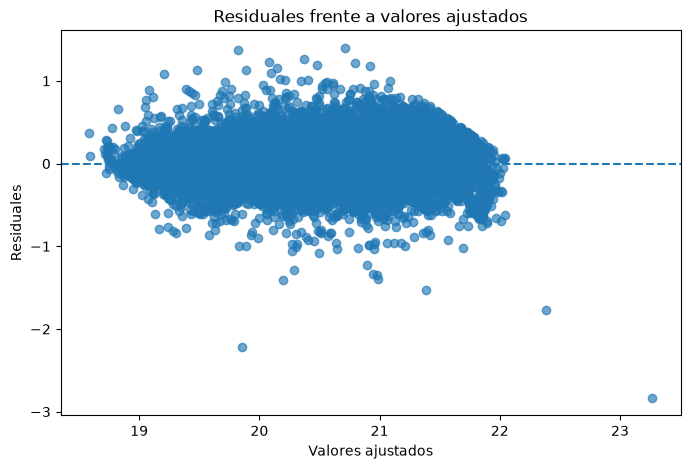

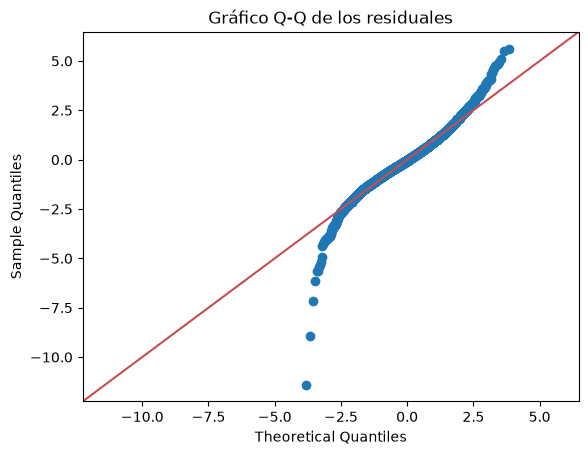

,prueba,estadistico,p_valor,H0
0,Jarque-Bera,6692.71168,0.0,normalidad
1,Breusch-Pagan,2079.43569,0.0,homocedasticidad
2,Ramsey RESET,75.89006,0.0,forma funcional adecuada
3,Durbin-Watson,1.97114,NaN,"sin autocorrelación de orden 1, lectura heurís..."


Jarque-Bera: se rechaza H0 al 5 %. los residuales no son normales.
Breusch-Pagan: se rechaza H0 al 5 %. hay evidencia de heterocedasticidad.
Ramsey RESET: se rechaza H0 al 5 %. hay evidencia de mala especificación de la forma funcional.
Durbin-Watson: estadístico = 1.9711. Sin p-valor, lectura heurística (≈2 sugiere ausencia de autocorrelación de orden 1).
Observaciones con residuos atípicos (|student| > 2): 834
Observaciones con alto leverage (hat > 0.002): 590
Observaciones influyentes (Cook D > 0.000): 886


In [301]:
ols_model = sm.OLS(
    np.log(y_train.loc[ols_features.index]),
    sm.add_constant(ols_features.astype(float), has_constant="add"),
).fit()
diagnostico_ols = DiagnosticoOLS(ols_model)
diagnostico_ols.reporte_completo(hc3=True)

### Lectura del OLS

Con las 18 variables seleccionadas el modelo explica el 89 % de la varianza del
log-precio en entrenamiento y el 74 % del precio en pesos fuera de muestra. Los
coeficientes tienen el signo esperado: la elasticidad precio-área es 0.64, cada
nivel de estrato suma cerca de un 17 % al precio, cada rango de antigüedad resta
un 3.4 % y cada kilómetro de distancia a un landmark negativo suma un 1.2 %. La
distancia al landmark positivo no es significativa.

Las pruebas rechazan los tres supuestos: hay heterocedasticidad (Breusch-Pagan),
por lo que la inferencia se hace con errores HC3, y con ellos parqueaderos,
habitaciones y baños dejan de ser significativos; los residuales tienen colas
pesadas (Jarque-Bera); y la prueba RESET rechaza la forma funcional lineal. Esto
último motiva un modelo no lineal como BART, que captura las interacciones entre
área, estrato y ubicación sin especificarlas.

# Modelo BART clasico

## Seleccionando 18 variables con IM

In [302]:
classic_bart = BARTAtrRegressor(
    trim=False, random_state=42, num_burnin=2000, num_mcmc=4000
)

classic_bart_pipeline = create_tree_selection_pipeline(
    classic_bart, n_features_to_select=18
)

In [303]:
cv_classic_bart_results = cross_validate_model_cached(
    classic_bart_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=1,
)
pd.DataFrame(cv_classic_bart_results)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_77455c76a8184957e0f342cc268c8a1a.pkl


5388

In [304]:
pd.DataFrame(cv_classic_bart_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,145.903559,247.905027,-3.440398e+08,-1.755693e+08,-0.165771,0.814505,41.885408,70.053627,-50.127011,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,153.327010,227.607632,-3.320219e+08,-1.732191e+08,-0.167888,0.830028,42.546584,70.920384,-52.343309,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,146.855911,229.117969,-3.583570e+08,-1.953567e+08,-0.184493,0.810131,40.429136,68.492377,-52.004517,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,150.890165,231.547618,-3.514867e+08,-1.799517e+08,-0.172777,0.816442,42.715980,70.327499,-52.936194,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,150.191846,228.775568,-3.589512e+08,-1.751428e+08,-0.171280,0.810888,42.348955,70.581592,-51.552795,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


In [305]:
@cached(
    cache_dir=CACHE_DIR,
    watch=[*PIPELINE_SOURCES, ROOT_DIR / "utils" / "bart_article.py"],
)
def mcmc_diagnostics(cv_results: dict[str, Any], X: pd.DataFrame):  # noqa: N803
    """One row per CV fold: convergence of sigma^2 and of f(x).

    f(x) is drawn on the fold's test rows. Loads one fitted fold (~2.6 GB)
    at a time and frees it before the next.
    """
    rows = []
    folds = tqdm(
        cv_results["test_indices"], desc="Diagnóstico MCMC", unit="fold"
    )
    for i, test in enumerate(folds):
        fitted = load_fold_estimator(cv_results, i)
        inner = fitted.named_steps["outliers"].regressor_.regressor_
        bart = inner[-1]
        features = inner[:-1].transform(
            fitted.named_steps["imputation"].transform(X.iloc[test])
        )
        f = bart.posterior_draws(features)  # (chain, draw, row)
        sigma2 = bart.model_.global_var_samples.reshape(f.shape[0], -1)
        del fitted, inner, bart, features
        gc.collect()

        idata = az.from_dict({"posterior": {"sigma2": sigma2, "f": f}})
        s = az.summary(idata, var_names=["sigma2"], round_to="none").iloc[0]
        rhat_f = az.rhat(idata, var_names=["f"])["f"].values
        ess_f = az.ess(idata, var_names=["f"], method="bulk")["f"].values
        rows.append(
            {
                "chains": f.shape[0],
                "draws": f.shape[1],
                "sigma2_mean": s["mean"],
                "sigma2_rhat": s["r_hat"],
                "sigma2_ess_bulk": s["ess_bulk"],
                "sigma2_ess_tail": s["ess_tail"],
                "sigma2_mcse_mean": s["mcse_mean"],
                "f_rhat_median": np.median(rhat_f),
                "f_rhat_max": rhat_f.max(),
                "f_pct_rhat_gt_1_01": 100 * np.mean(rhat_f > 1.01),
                "f_ess_bulk_median": np.median(ess_f),
                "f_ess_bulk_min": ess_f.min(),
            }
        )
        del f, sigma2, idata
    return pd.DataFrame(rows).rename_axis("fold")

In [306]:
diagnostico_classic_18 = mcmc_diagnostics(cv_classic_bart_results, X_train)
diagnostico_classic_18

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\mcmc_diagnostics_5ad50cf50d921c89ae9939a2500e604d.pkl


,chains,draws,sigma2_mean,sigma2_rhat,sigma2_ess_bulk,sigma2_ess_tail,sigma2_mcse_mean,f_rhat_median,f_rhat_max,f_pct_rhat_gt_1_01,f_ess_bulk_median,f_ess_bulk_min
fold,,,,,,,,,,,,
0,2,4000,0.038180,1.377025,4.331136,14.993255,0.000374,1.426275,2.450394,99.887101,4.131349,2.426678
1,2,4000,0.038667,1.261936,5.554226,8.786677,0.000297,1.438558,2.711409,99.830604,4.065769,2.338277
2,2,4000,0.038576,1.610461,3.304823,6.765326,0.000466,1.431529,2.538165,99.915302,4.118285,2.397378
3,2,4000,0.038046,1.564956,3.441662,5.162073,0.000521,1.442916,2.629654,99.943535,4.025092,2.358116
4,2,4000,0.037792,1.328697,4.705046,11.114643,0.000313,1.429182,2.514113,99.887069,4.124203,2.401664


## Traceplot

Sin caché para 'extract_chains' o hubo cambios; calculando...
Resultado guardado en: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\extract_chains_40db5e7359af92eb7d6a5a17e3674566.pkl


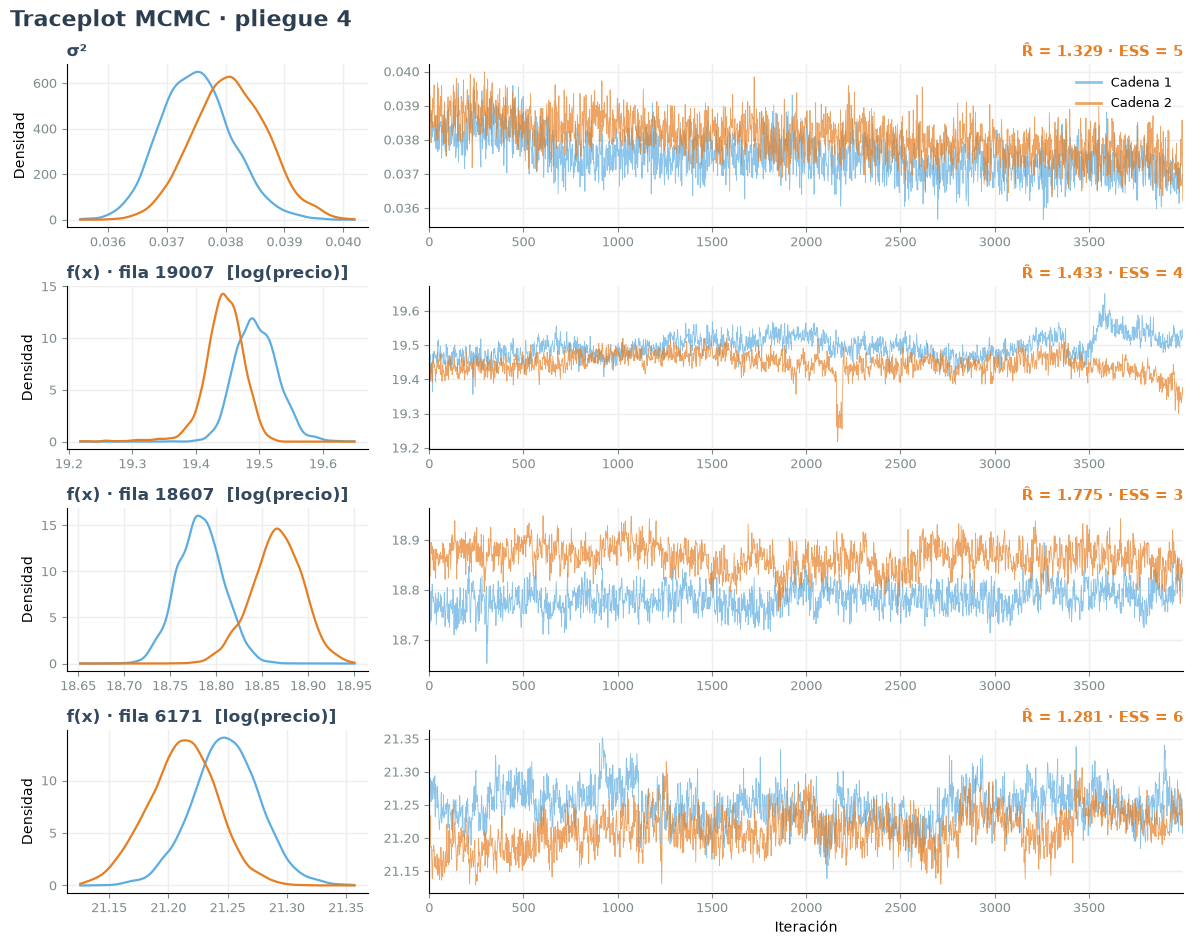

In [307]:
# Loading a fold is the slow part, so the chains are cached; the figure
# redraws from them.
extract_chains_cached = cached(
    cache_dir=CACHE_DIR,
    watch=[
        *PIPELINE_SOURCES,
        ROOT_DIR / "utils" / "bart_article.py",
        ROOT_DIR / "utils" / "mcmc_traceplot.py",
    ],
)(extract_chains)

traza_classic_18 = extract_chains_cached(cv_classic_bart_results, X_train)
traza_classic_18["fig"] = plot_trace(traza_classic_18)

## Shap Explanation

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\compute_shap_5aacb8b172fc9d82bd1677917c3bca0a.pkl


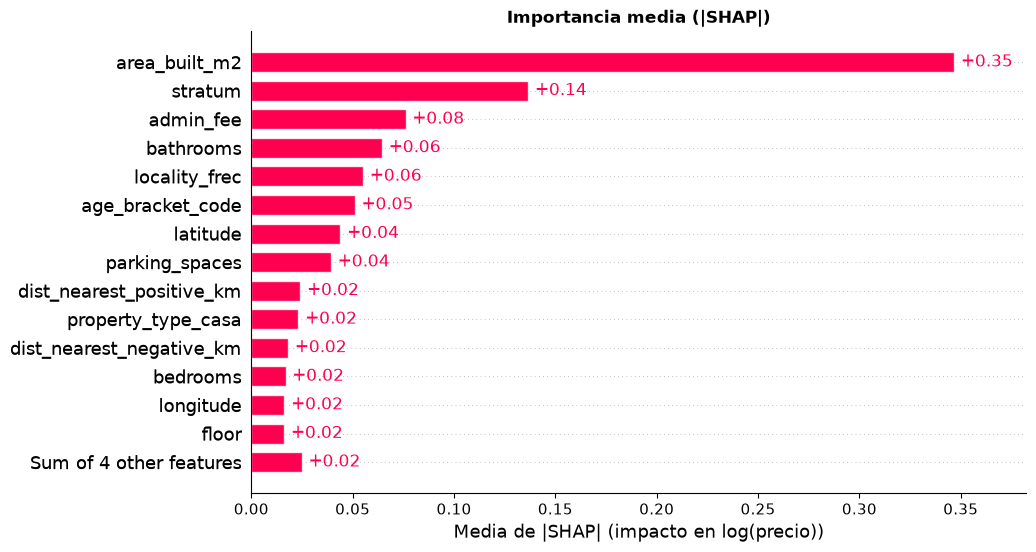

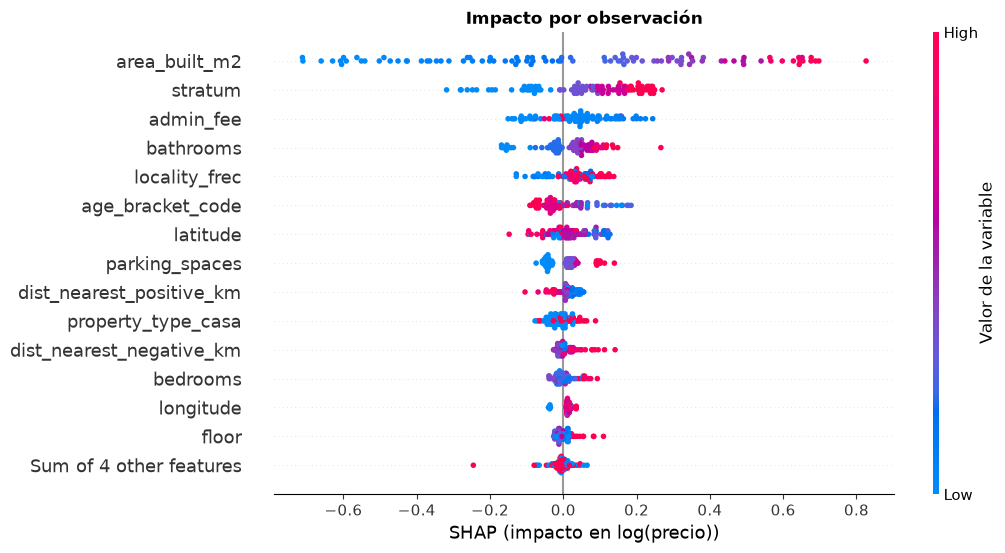

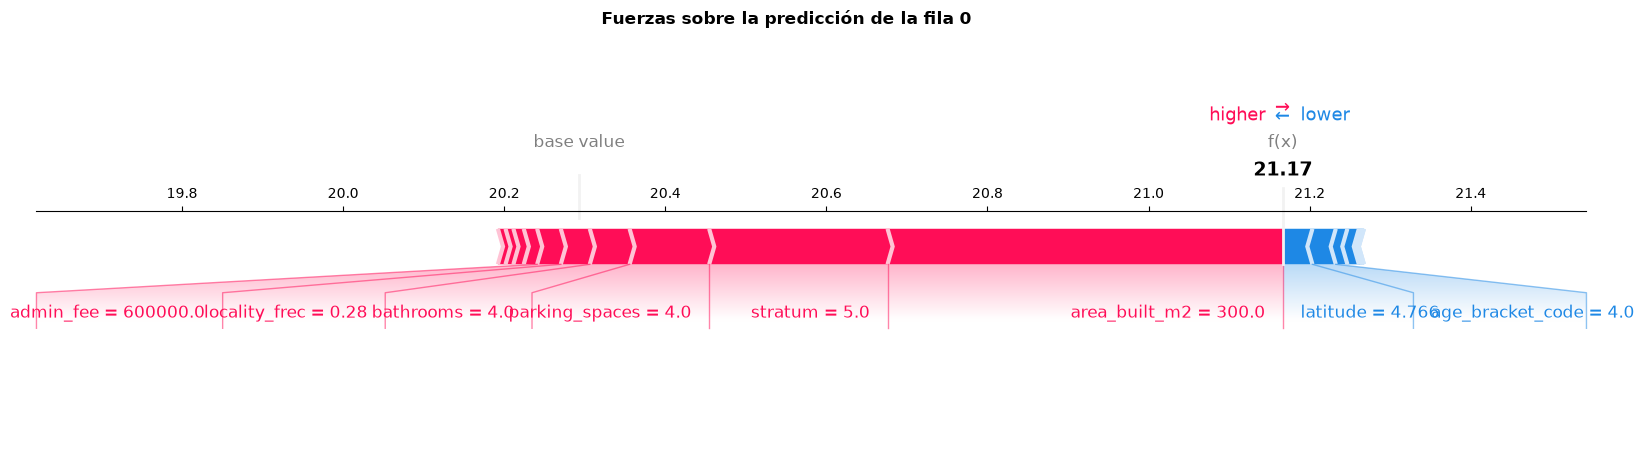

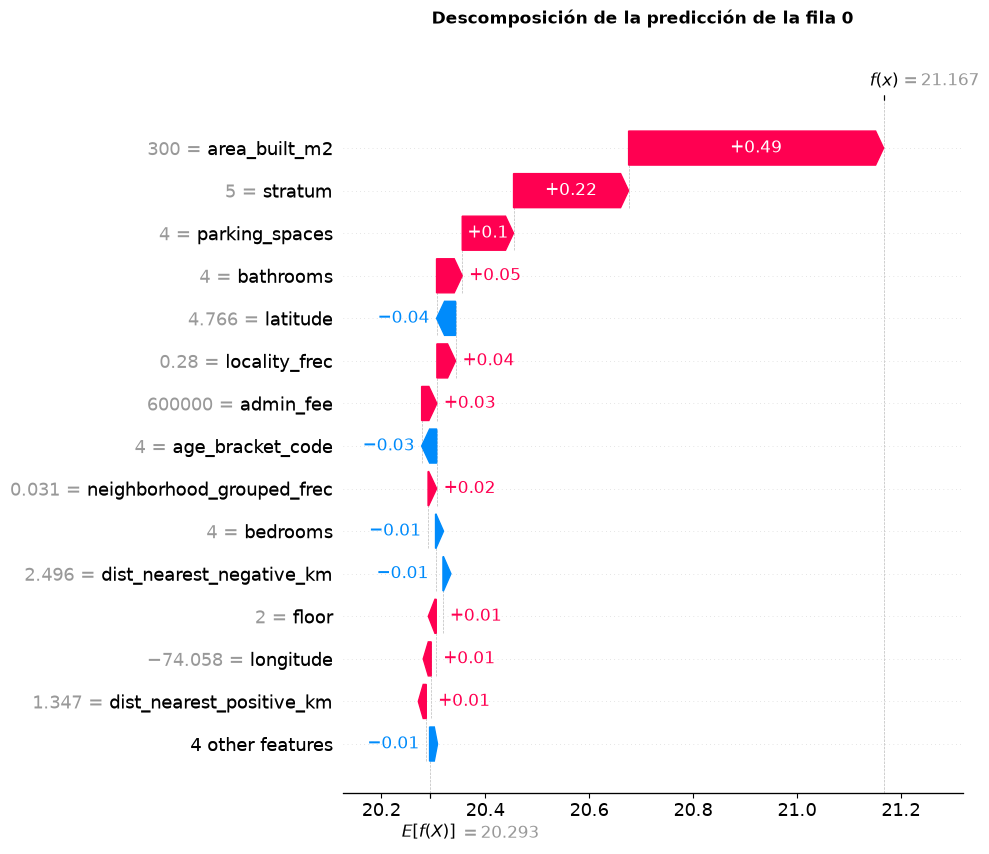

In [308]:
# BART has no tree explainer in shap: the permutation one runs every
# posterior draw per prediction, so the slow half is cached and the
# sample kept small.
compute_shap_cached = cached(
    cache_dir=CACHE_DIR,
    watch=[ROOT_DIR / "utils" / "shap_explanaitor.py"],
)(compute_shap)

shap_classic_bart = compute_shap_cached(
    cv_classic_bart_results, X_train, n_explain=100, n_background=50
)
shap_classic_bart["figs"] = plot_shap(shap_classic_bart["explanation"])

## Seleccionando 6 variables con IM

In [309]:
classic_bart_6 = BARTAtrRegressor(
    trim=False, random_state=42, num_burnin=2000, num_mcmc=4000
)

classic_bart_6_pipeline = create_tree_selection_pipeline(
    classic_bart_6, n_features_to_select=6
)

In [310]:
cv_classic_bart_6_results = cross_validate_model_cached(
    classic_bart_6_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=1,
)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_718bed6d4a9a17a975a828f063d0f15b.pkl


35567

In [311]:
pd.DataFrame(cv_classic_bart_6_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,161.360896,163.505448,-4.054520e+08,-2.162219e+08,-0.218659,0.742372,35.732430,63.110358,-50.917302,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,159.651150,173.274040,-3.641664e+08,-1.918663e+08,-0.190858,0.795523,36.758893,65.330322,-52.428007,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,156.284662,151.946500,-4.064921e+08,-2.280311e+08,-0.227249,0.755699,34.810841,61.293055,-53.811406,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,156.890849,153.057867,-4.001426e+08,-2.071209e+08,-0.208139,0.762105,37.154150,63.862225,-53.557312,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,154.205124,161.415022,-4.222775e+08,-2.197849e+08,-0.234144,0.738275,36.561265,63.382270,-54.432524,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


El rendimiento es pero que con las 18 variables

In [312]:
diagnostico_classic_6 = mcmc_diagnostics(cv_classic_bart_6_results, X_train)
diagnostico_classic_6

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\mcmc_diagnostics_cfb82d519055761bdd195ae0b72bc1bf.pkl


,chains,draws,sigma2_mean,sigma2_rhat,sigma2_ess_bulk,sigma2_ess_tail,sigma2_mcse_mean,f_rhat_median,f_rhat_max,f_pct_rhat_gt_1_01,f_ess_bulk_median,f_ess_bulk_min
fold,,,,,,,,,,,,
0,2,4000,0.051208,1.509954,3.639933,12.621239,0.000752,1.403609,2.598405,99.858877,4.298750,2.366326
1,2,4000,0.051498,1.777362,2.952980,5.251302,0.000971,1.450353,2.641073,100.000000,4.007779,2.364091
2,2,4000,0.052749,1.582818,3.377601,10.021271,0.000737,1.438465,2.556545,99.915302,4.062523,2.390087
3,2,4000,0.052076,1.452580,3.876357,10.126265,0.000618,1.430083,2.487736,99.915302,4.106428,2.407054
4,2,4000,0.051184,1.524977,3.566432,6.968894,0.000663,1.418546,2.554351,99.887069,4.185567,2.398076


## Traceplot

Sin caché para 'extract_chains' o hubo cambios; calculando...
Resultado guardado en: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\extract_chains_20ad818e1f678dc4f681d706bee269b1.pkl


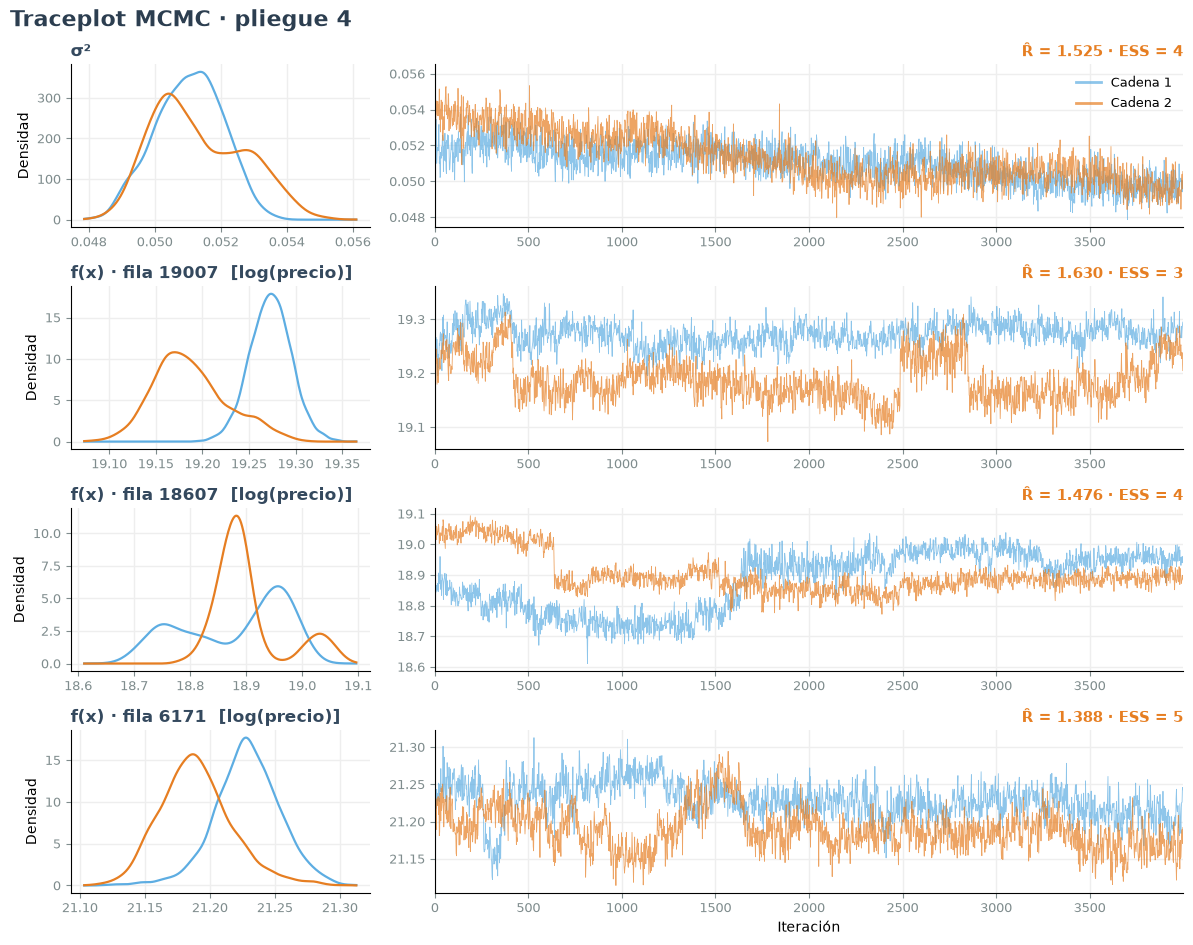

In [313]:
traza_classic_6 = extract_chains_cached(cv_classic_bart_6_results, X_train)
traza_classic_6["fig"] = plot_trace(traza_classic_6)

## Shap Explanation

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\compute_shap_83bd9941f9a4c7939734ea475aff5141.pkl


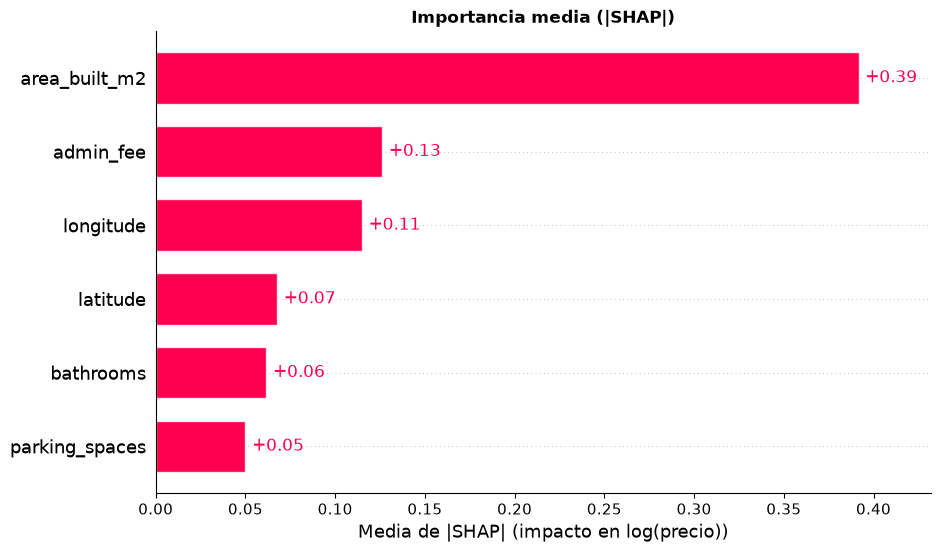

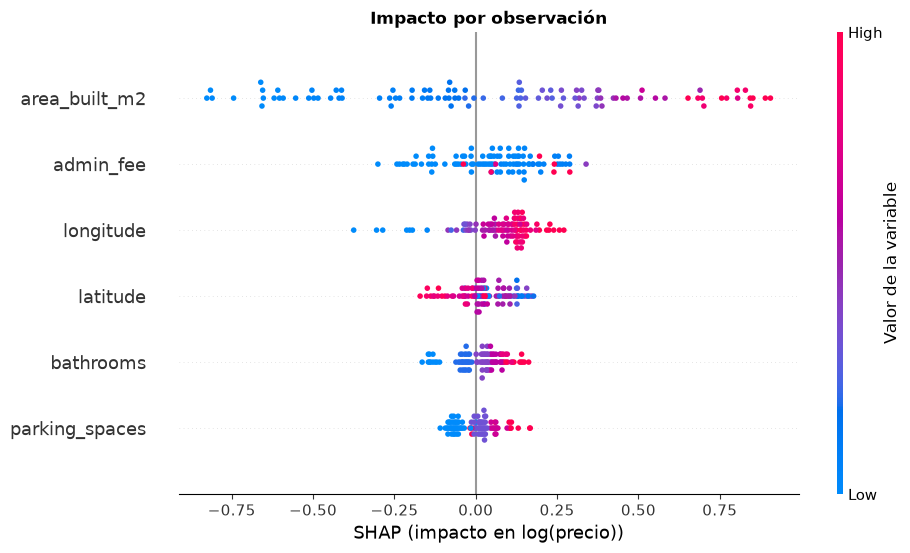

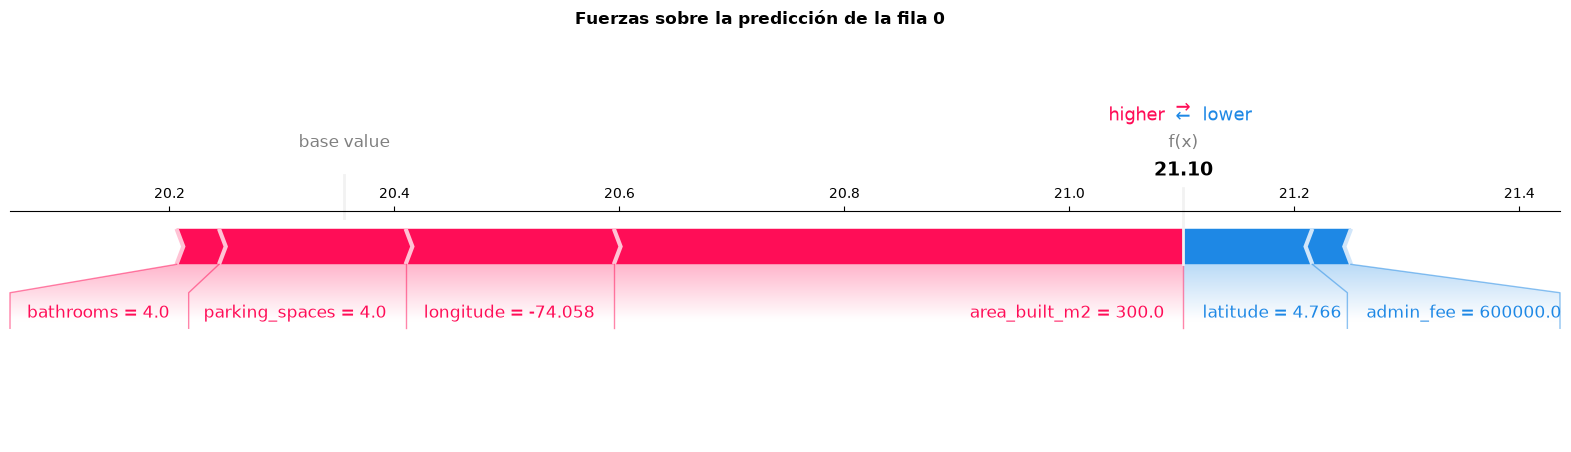

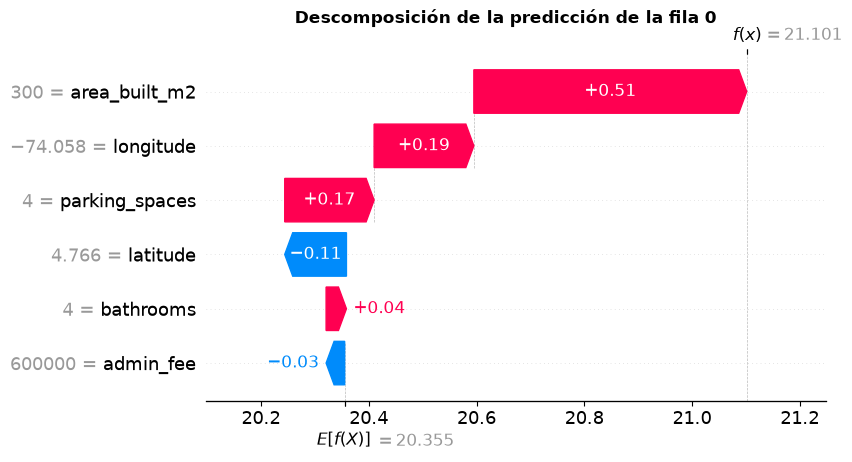

In [314]:
shap_classic_bart_6 = compute_shap_cached(
    cv_classic_bart_6_results, X_train, n_explain=100, n_background=50
)
shap_classic_bart_6["figs"] = plot_shap(shap_classic_bart_6["explanation"])

# Modelo Random Forest

*Random Forest* (Breiman, 2001) promedia muchos árboles de regresión
profundos. Cada árbol se ajusta sobre una muestra *bootstrap* de las filas y,
en cada división, solo considera un subconjunto aleatorio de variables; así los
árboles quedan poco correlacionados y su promedio reduce la varianza de un
árbol individual sin aumentar mucho su sesgo. A diferencia de BART, no hay una
previa que regularice los árboles ni una distribución posterior: es un
estimador puntual.

Se usa el mismo `create_tree_selection_pipeline` que en BART, así que la
imputación, los atípicos, la codificación y la selección por información mutua
son idénticas y las métricas de la validación cruzada son comparables.

| Hiperparámetro | Valor | Motivo |
|---|---|---|
| `n_estimators` | 500 | `ntree` por defecto de `randomForest` en R |
| `max_features` | 1/3 | p/3, la recomendación de Breiman para regresión |
| `min_samples_leaf` | 5 | `nodesize` por defecto en regresión; además aligera el pipeline guardado |
| `n_jobs` | 2 | × 2 *folds* en paralelo = 4 núcleos |

## Seleccionando 18 variables con IM

In [315]:
from sklearn.ensemble import RandomForestRegressor

random_forest = RandomForestRegressor(
    n_estimators=500,
    max_features=1 / 3,
    min_samples_leaf=5,
    n_jobs=2,
    random_state=42,
)

random_forest_pipeline = create_tree_selection_pipeline(
    random_forest, n_features_to_select=18
)

In [316]:
cv_random_forest_results = cross_validate_model_cached(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=2,
)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_bc1a1f0f920f66111652254a775f3cdd.pkl


24833

In [317]:
pd.DataFrame(cv_random_forest_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,49.262861,17.511627,-3.417495e+08,-1.714474e+08,-0.166336,0.816967,44.651425,71.097940,-50.889077,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,50.387287,17.165648,-3.501215e+08,-1.696547e+08,-0.161155,0.810991,45.454545,71.936759,-52.682101,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,51.596673,14.196940,-3.545535e+08,-1.856608e+08,-0.174798,0.814140,43.704122,69.960474,-53.557312,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,51.606165,14.112335,-3.672033e+08,-1.750486e+08,-0.168936,0.799659,46.019198,70.750988,-52.625635,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,32.638389,12.358088,-3.700045e+08,-1.763934e+08,-0.178828,0.799062,43.929983,70.299266,-54.517222,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


## Shap Explanation

 98%|===================| 197/200 [00:50<00:00]        

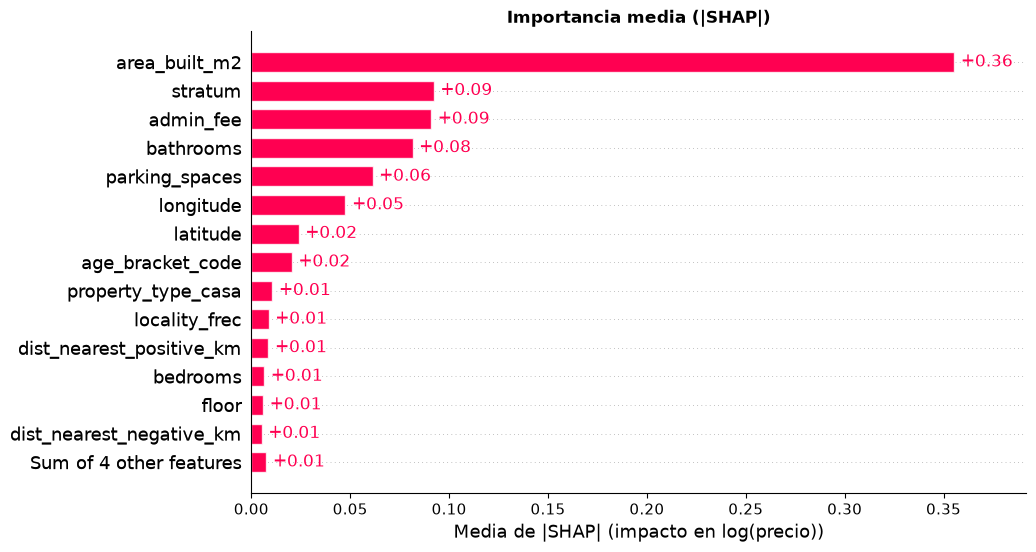

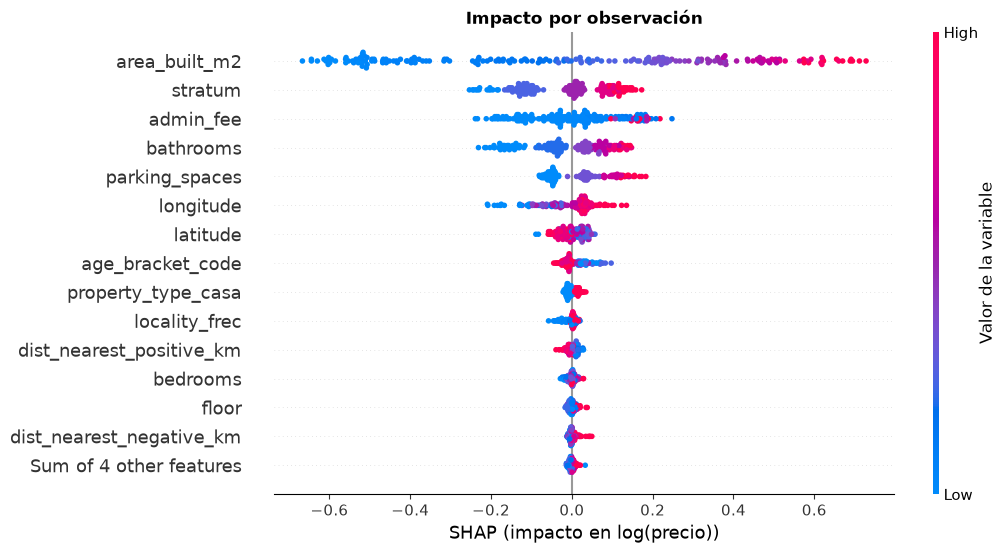

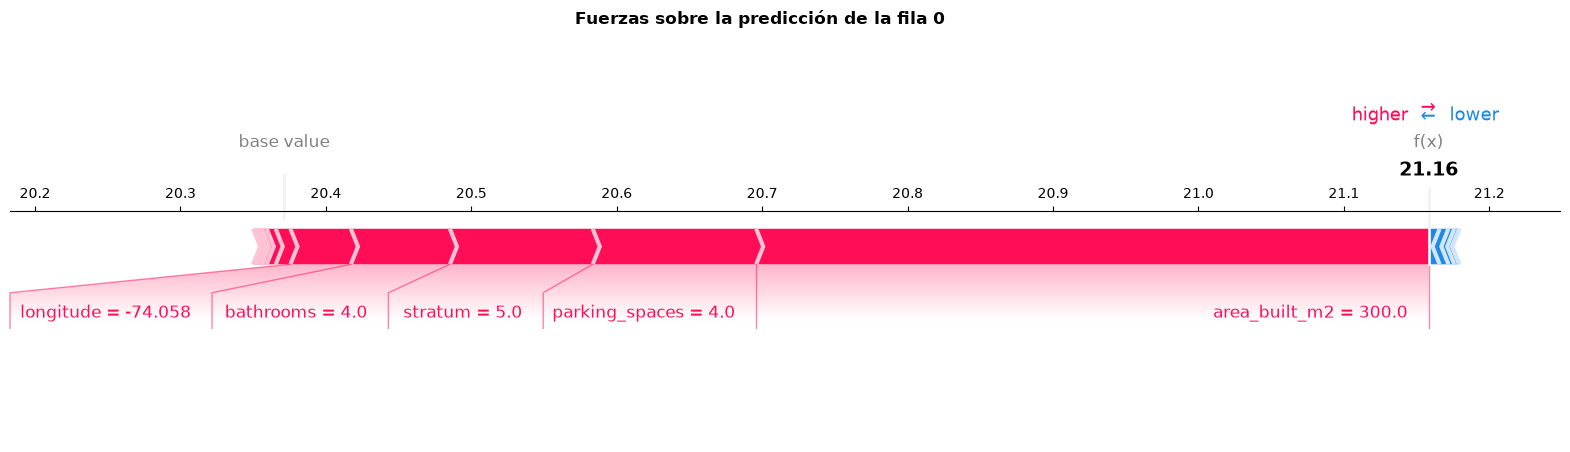

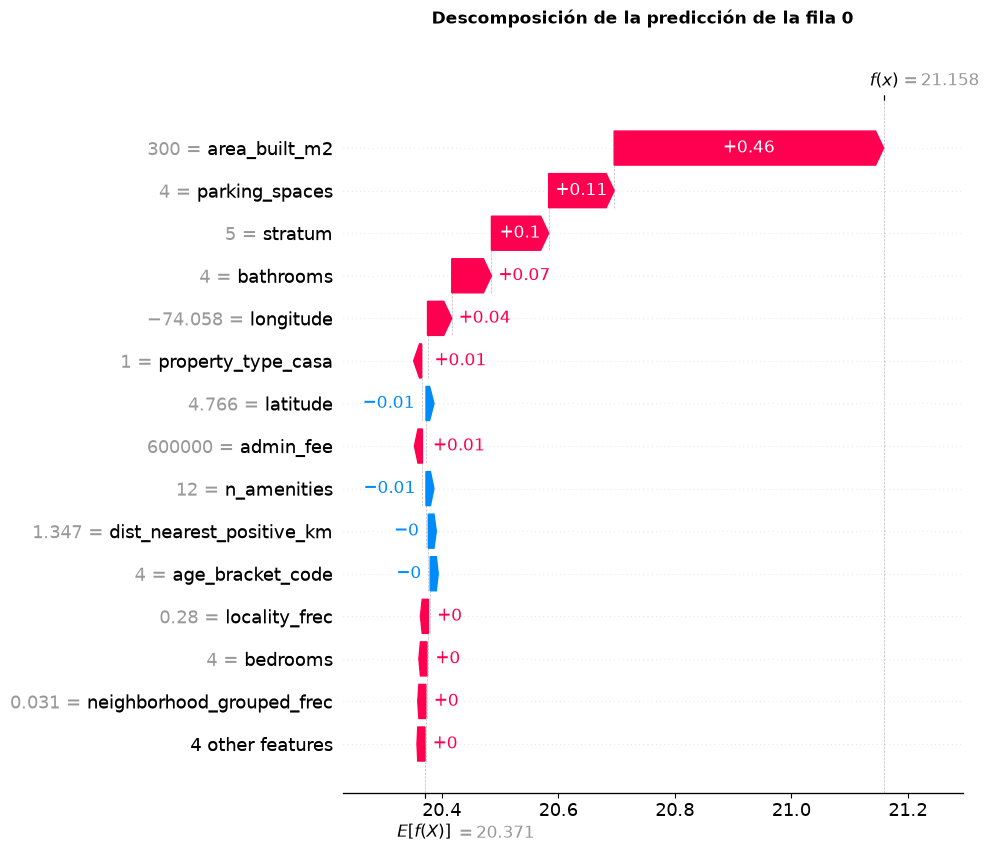

In [318]:
shap_random_forest = shap_report(cv_random_forest_results, X_train)

## Seleccionando 6 variables con IM

In [319]:
random_forest_6 = RandomForestRegressor(
    n_estimators=500,
    max_features=1 / 3,
    min_samples_leaf=5,
    n_jobs=2,
    random_state=42,
)

random_forest_6_pipeline = create_tree_selection_pipeline(
    random_forest_6, n_features_to_select=6
)

In [320]:
cv_random_forest_6_results = cross_validate_model_cached(
    random_forest_6_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=2,
)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_1764829bd248b96641b06e913693e3ff.pkl


35435

In [321]:
pd.DataFrame(cv_random_forest_6_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,49.502805,13.016266,-3.663122e+08,-1.918872e+08,-0.196064,0.789711,40.699972,66.440869,-51.820491,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,50.039010,13.014068,-3.600815e+08,-1.828581e+08,-0.179901,0.800085,40.033879,67.814794,-52.907962,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,42.374487,12.933885,-3.812755e+08,-2.105490e+08,-0.211050,0.785069,38.763411,65.302089,-53.642010,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,40.771856,12.865099,-3.903451e+08,-1.974027e+08,-0.203484,0.773612,40.965556,66.741954,-53.896104,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,29.845772,12.262161,-4.028466e+08,-2.059393e+08,-0.223079,0.761807,40.513834,65.189159,-56.070017,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


## Shap Explanation

 98%|===================| 196/200 [00:41<00:00]        

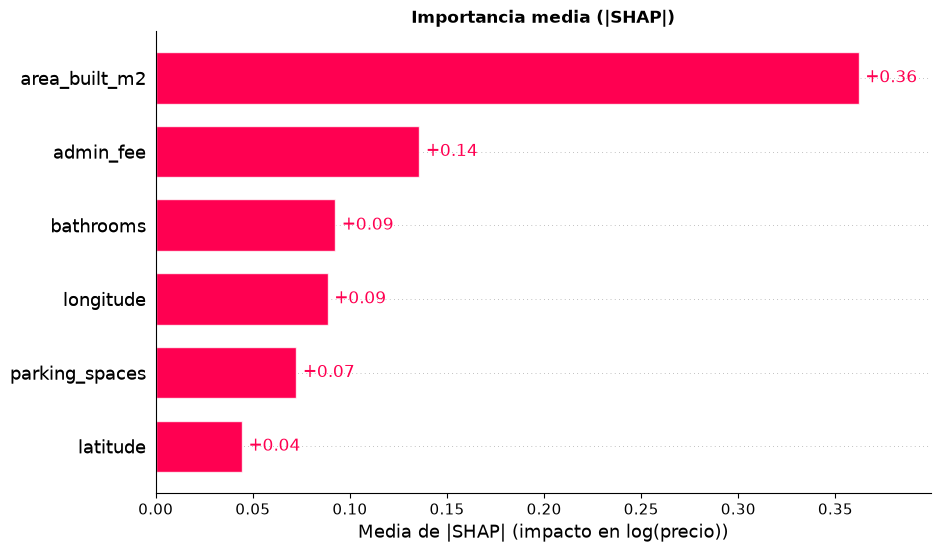

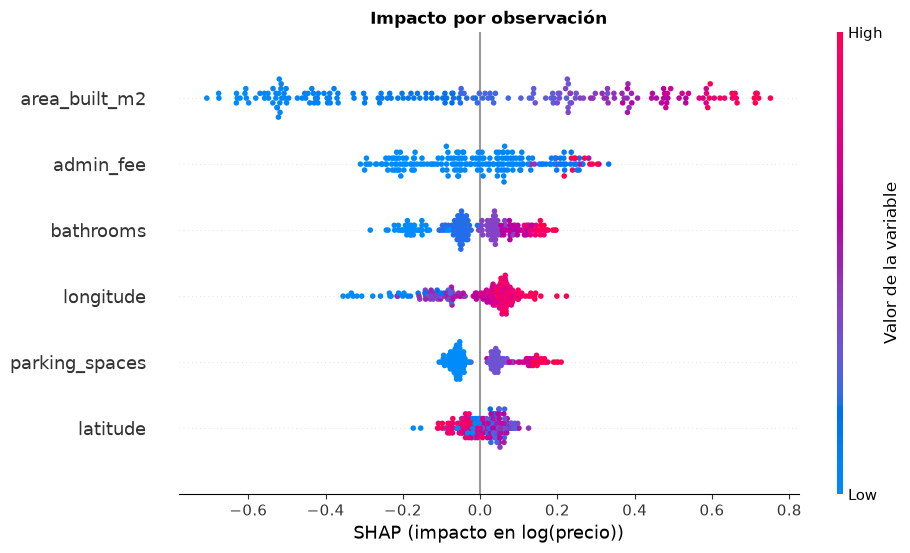

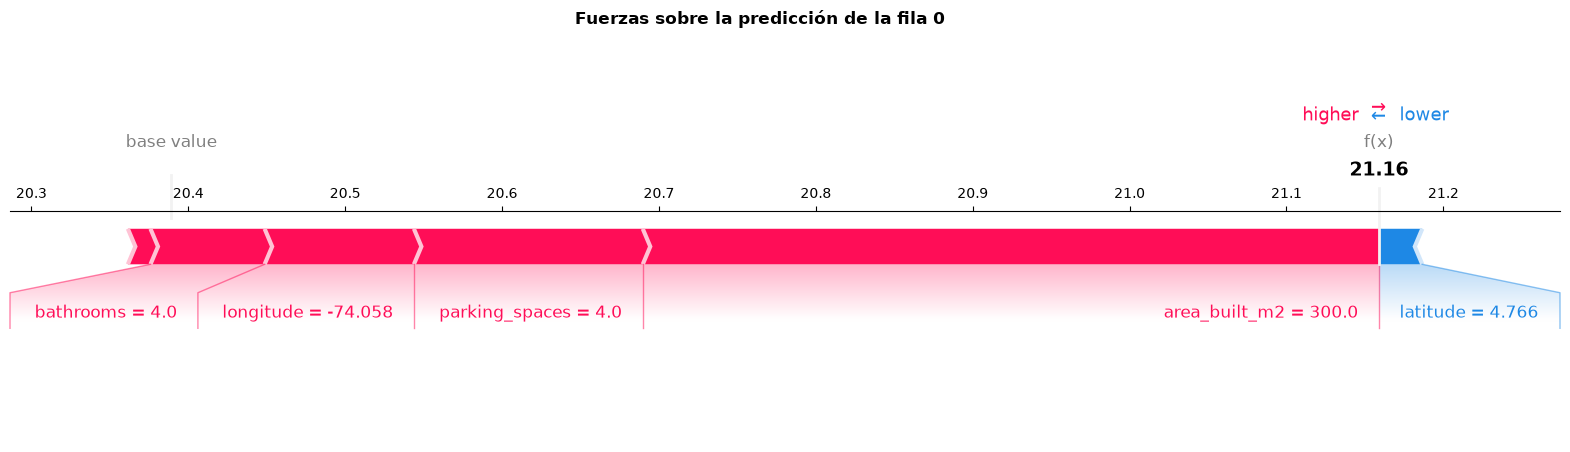

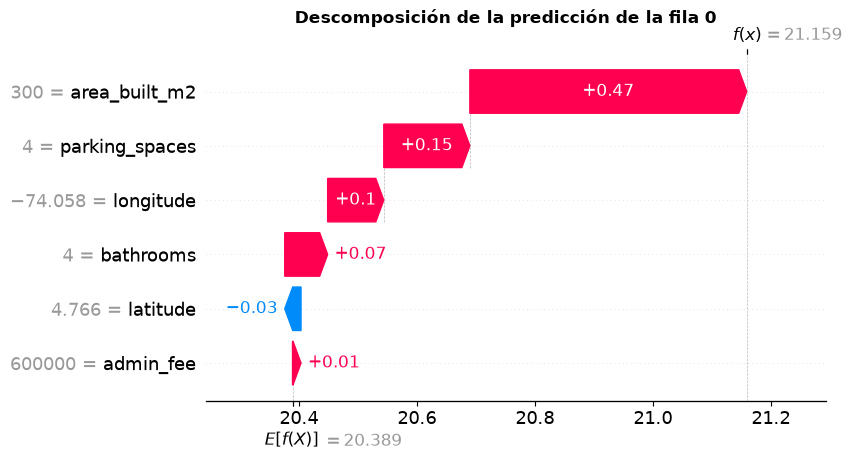

In [322]:
shap_random_forest_6 = shap_report(cv_random_forest_6_results, X_train)

# Modelo XGBoost

*XGBoost* (Chen y Guestrin, 2016) es *gradient boosting* de árboles: los
árboles se agregan uno a uno y cada nuevo árbol se ajusta al gradiente de la
pérdida del ensamble actual, es decir, corrige lo que los anteriores aún no
explican. Su contribución se encoge con la tasa de aprendizaje y los pesos de
las hojas se penalizan con L2 (`reg_lambda`). Es el análogo frecuentista más
cercano a BART: ambos son una suma de árboles pequeños, pero BART los ajusta
con *backfitting* MCMC bajo una previa que los encoge, mientras que XGBoost los
optimiza de forma secuencial (Chipman et al., 2010).

| Hiperparámetro | Valor | Motivo |
|---|---|---|
| `n_estimators`, `learning_rate` | 600, 0.05 | tasa baja con suficientes árboles, sin *early stopping* para no sacar un conjunto de validación del *fold* |
| `max_depth` | 6 | valor por defecto: árboles poco profundos, como en BART |
| `subsample`, `colsample_bytree` | 0.8, 0.8 | submuestreo de filas y columnas por árbol, reduce el sobreajuste |
| `tree_method` | `"hist"` | divisiones sobre histogramas, más rápido |
| `n_jobs` | 2 | × 2 *folds* en paralelo = 4 núcleos |

No se hace búsqueda de hiperparámetros; hacerla bien exigiría una validación
cruzada anidada.

## Seleccionando 18 variables con IM

In [323]:
from xgboost import XGBRegressor

xgboost_model = XGBRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=2,
    random_state=42,
)

xgboost_model_pipeline = create_tree_selection_pipeline(
    xgboost_model, n_features_to_select=18
)

In [324]:
cv_xgboost_results = cross_validate_model_cached(
    xgboost_model_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=2,
)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_71b5d73fe2e92f1892bda9d5dbbd3b13.pkl


22513

In [325]:
pd.DataFrame(cv_xgboost_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,44.365439,12.038986,-3.294999e+08,-1.633697e+08,-0.153818,0.829853,45.300593,73.609935,-49.675416,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,44.419273,11.990622,-3.293264e+08,-1.606384e+08,-0.151297,0.832777,47.063806,74.788255,-51.496330,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,39.219114,12.009376,-3.318583e+08,-1.742480e+08,-0.159524,0.837173,44.551101,72.953134,-51.891587,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,37.942189,11.721244,-3.548899e+08,-1.655795e+08,-0.155651,0.812870,48.051948,73.771880,-51.863354,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,25.955591,10.465636,-3.483860e+08,-1.658648e+08,-0.167503,0.821856,46.979108,73.404856,-52.540937,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


## Shap Explanation

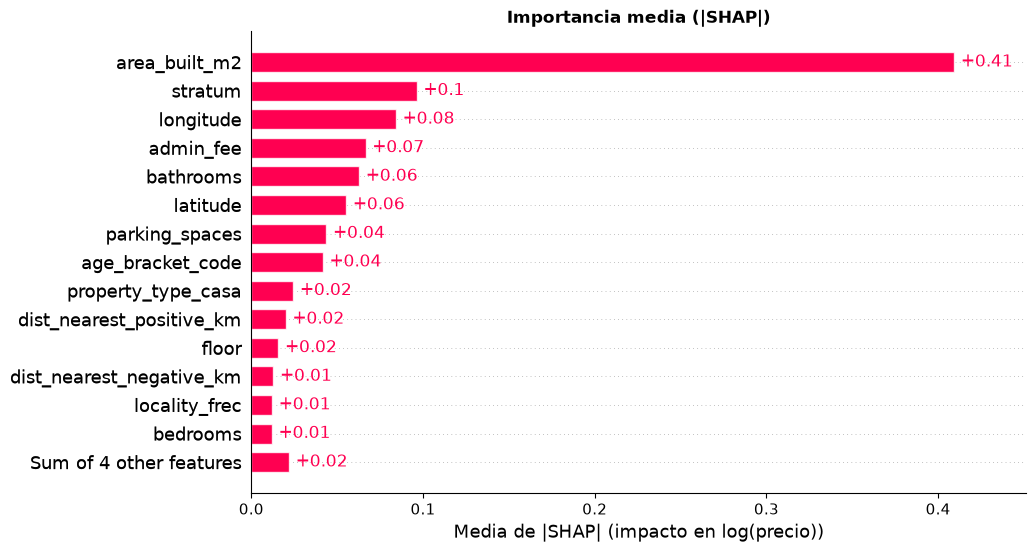

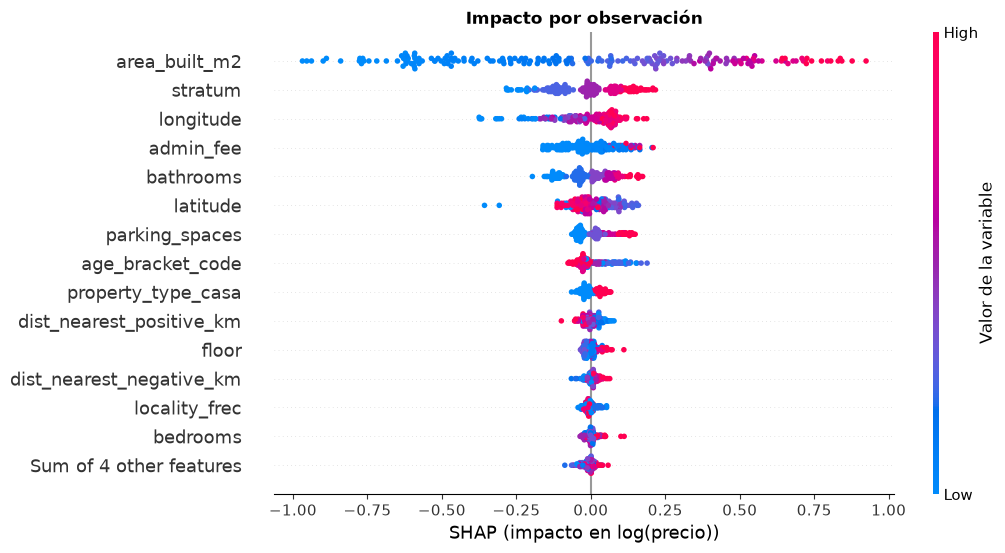

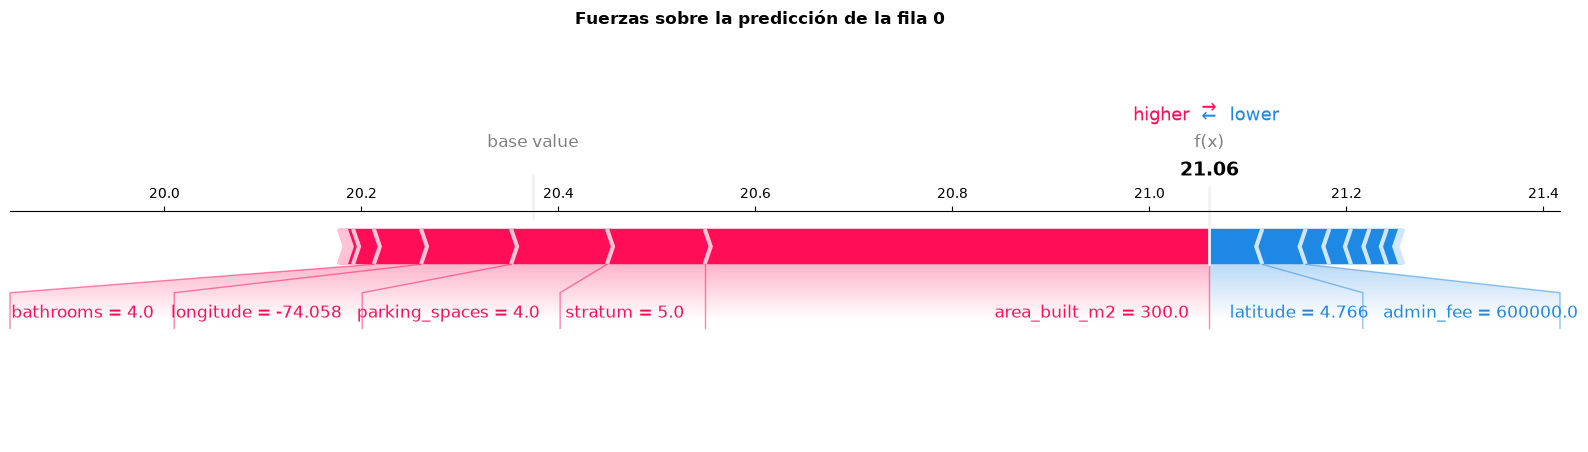

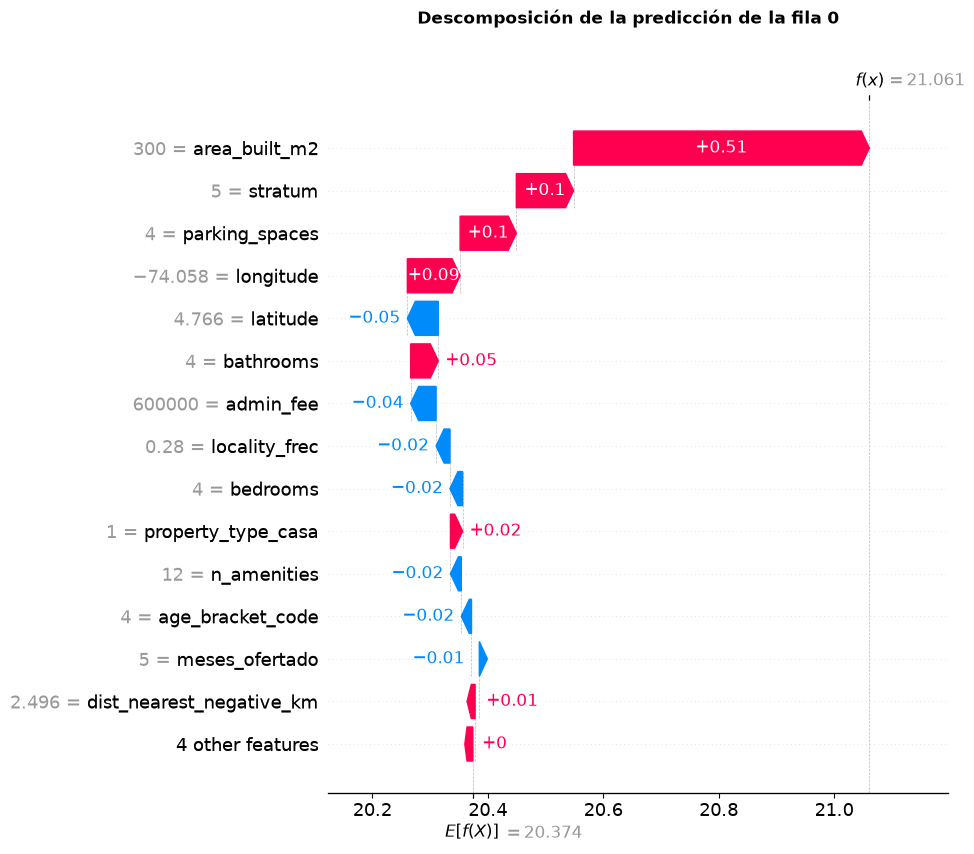

In [326]:
shap_xgboost = shap_report(cv_xgboost_results, X_train)

## Seleccionando 6 variables con IM

In [327]:
xgboost_model_6 = XGBRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=2,
    random_state=42,
)

xgboost_model_6_pipeline = create_tree_selection_pipeline(
    xgboost_model_6, n_features_to_select=6
)

In [328]:
cv_xgboost_6_results = cross_validate_model_cached(
    xgboost_model_6_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=2,
)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_4d588ad3bb734b26251c55b197acc96f.pkl


35373

In [329]:
pd.DataFrame(cv_xgboost_6_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,42.850054,12.555670,-3.630499e+08,-1.881682e+08,-0.187415,0.793440,41.941857,68.642393,-49.534293,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,43.459601,12.785438,-3.479700e+08,-1.758479e+08,-0.170094,0.813307,41.417278,69.847544,-51.581028,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,40.629425,11.388970,-3.700267e+08,-2.058103e+08,-0.202038,0.797564,39.920949,66.854884,-52.258611,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,39.494478,11.286965,-3.787152e+08,-1.875687e+08,-0.187941,0.786901,43.252400,69.678148,-53.077357,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,28.316808,10.176071,-4.022761e+08,-2.036740e+08,-0.219348,0.762481,41.163185,66.996047,-54.093732,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


## Shap Explanation

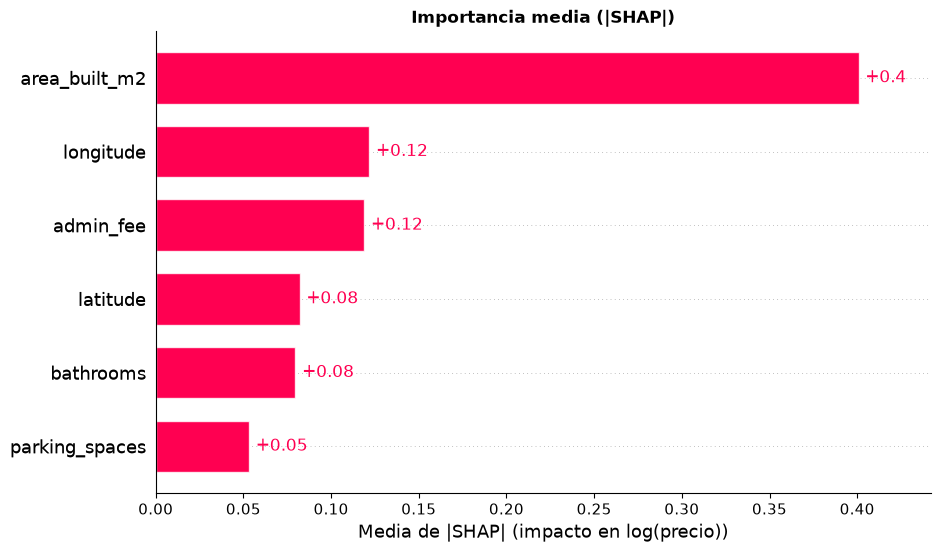

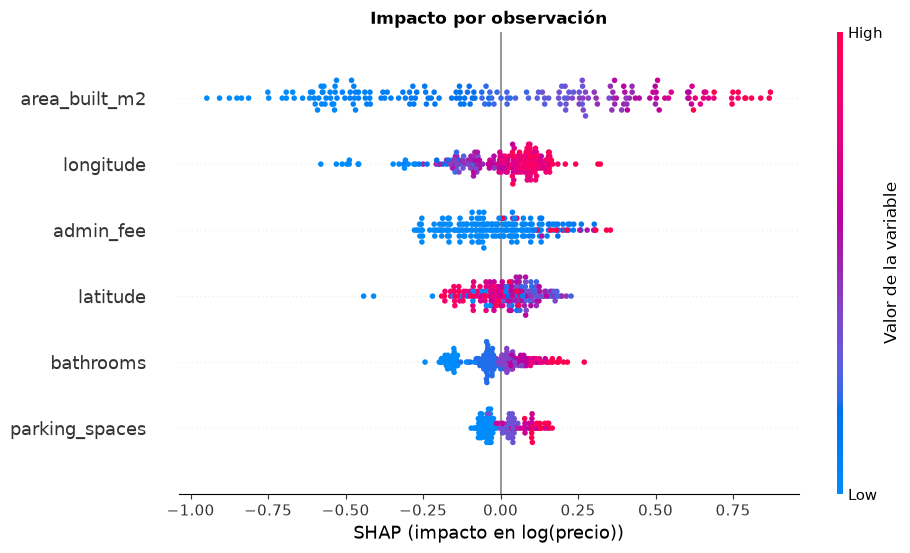

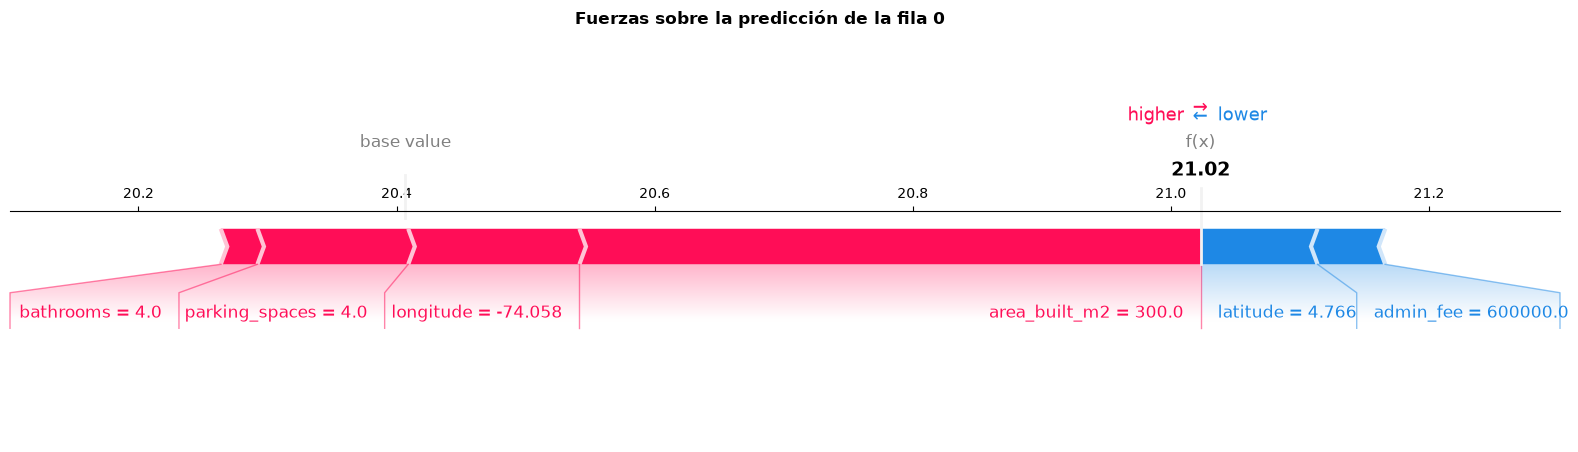

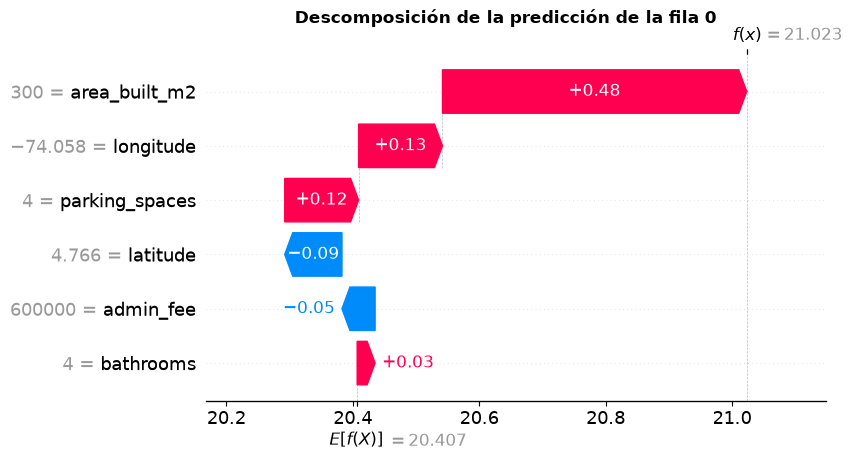

In [330]:
shap_xgboost_6 = shap_report(cv_xgboost_6_results, X_train)

# Modelo LightGBM

*LightGBM* (Ke et al., 2017) también es *gradient boosting* de árboles, con dos
diferencias frente a XGBoost: los árboles crecen por hojas (*leaf-wise*),
dividiendo siempre la hoja que más reduce la pérdida, y no por niveles; y las
variables se discretizan en histogramas desde el inicio. Suele ser más rápido
con resultados similares, aunque el crecimiento por hojas sobreajusta con más
facilidad, lo que se controla con `num_leaves` y `min_child_samples`.

| Hiperparámetro | Valor | Motivo |
|---|---|---|
| `n_estimators`, `learning_rate` | 600, 0.05 | los mismos que en XGBoost, para compararlos |
| `num_leaves` | 31 | valor por defecto; equivale en tamaño a un árbol de profundidad ~5 |
| `min_child_samples` | 20 | mínimo de filas por hoja, frena el sobreajuste del crecimiento por hojas |
| `subsample`, `subsample_freq`, `colsample_bytree` | 0.8, 1, 0.8 | submuestreo como en XGBoost; `subsample` solo actúa con `subsample_freq > 0` |
| `verbose` | -1 | silencia los avisos por *fold* |
| `n_jobs` | 2 | × 2 *folds* en paralelo = 4 núcleos |

## Seleccionando 18 variables con IM

In [331]:
from lightgbm import LGBMRegressor

lightgbm_model = LGBMRegressor(
    n_estimators=600,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    n_jobs=2,
    random_state=42,
    verbose=-1,
)

lightgbm_model_pipeline = create_tree_selection_pipeline(
    lightgbm_model, n_features_to_select=18
)

In [332]:
cv_lightgbm_results = cross_validate_model_cached(
    lightgbm_model_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=2,
)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_97c0c716e48108f7e8f44a0cff0a1871.pkl


22862

In [333]:
pd.DataFrame(cv_lightgbm_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,40.311646,11.917758,-3.273199e+08,-1.640889e+08,-0.154913,0.832097,44.820773,73.101891,-49.901214,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,40.254547,11.873942,-3.208588e+08,-1.614912e+08,-0.152807,0.841265,46.612084,73.884811,-51.439864,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,39.119191,12.055636,-3.366067e+08,-1.790807e+08,-0.164135,0.832480,44.748730,72.049689,-52.569170,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,37.679516,11.943888,-3.461220e+08,-1.647019e+08,-0.153840,0.822002,47.797854,73.687182,-52.032750,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,28.108253,12.738652,-3.492327e+08,-1.668029e+08,-0.165902,0.820989,45.341615,73.094297,-51.863354,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


## Shap Explanation

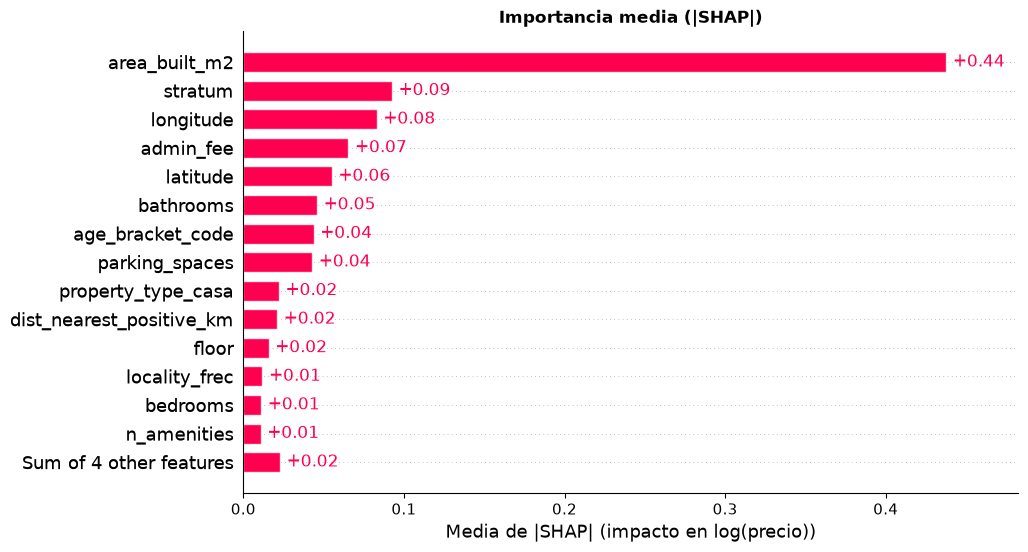

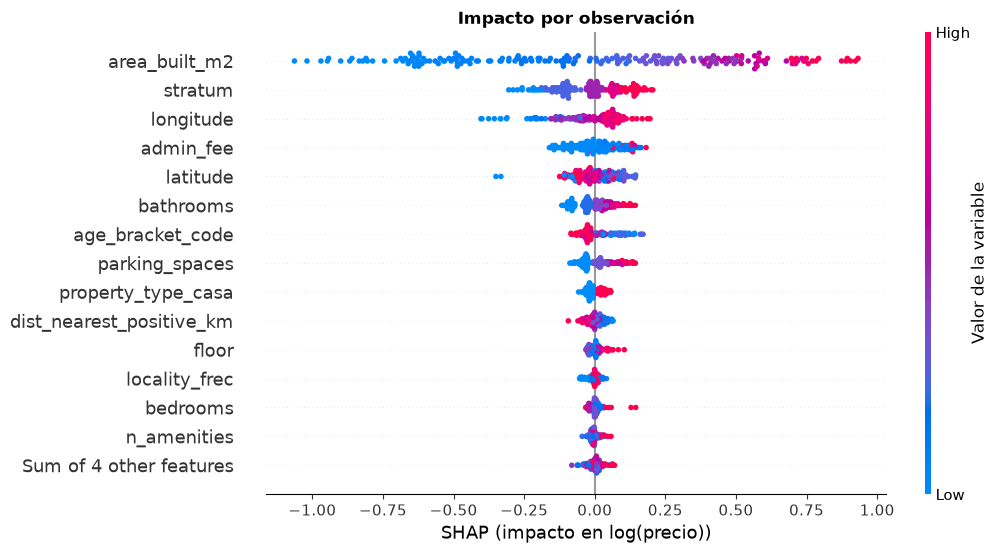

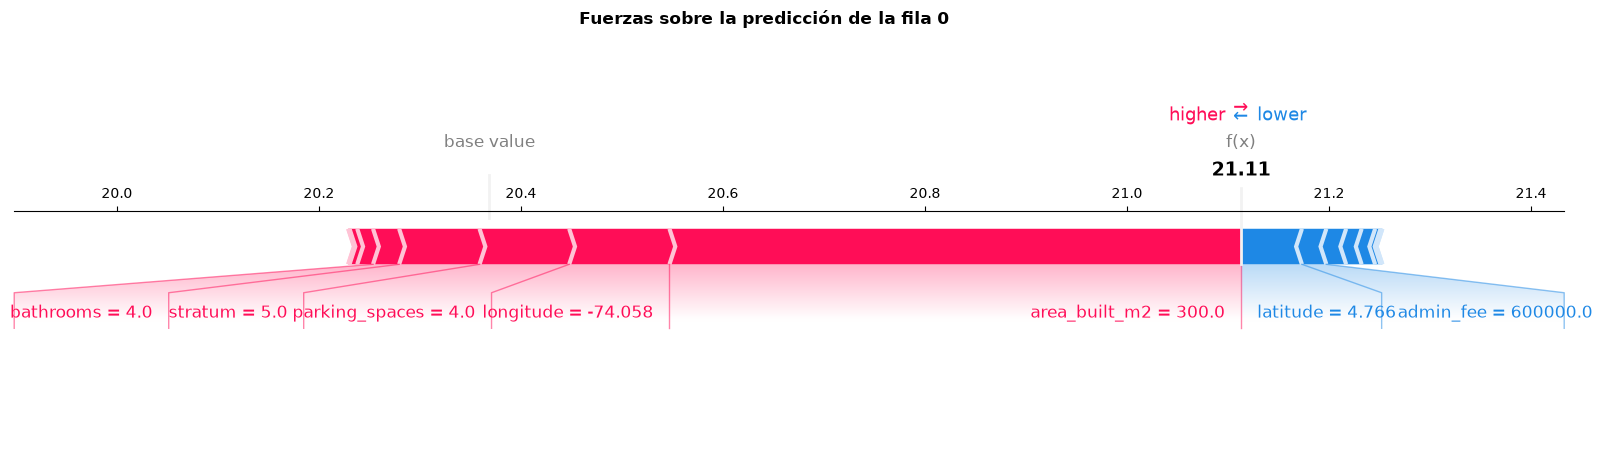

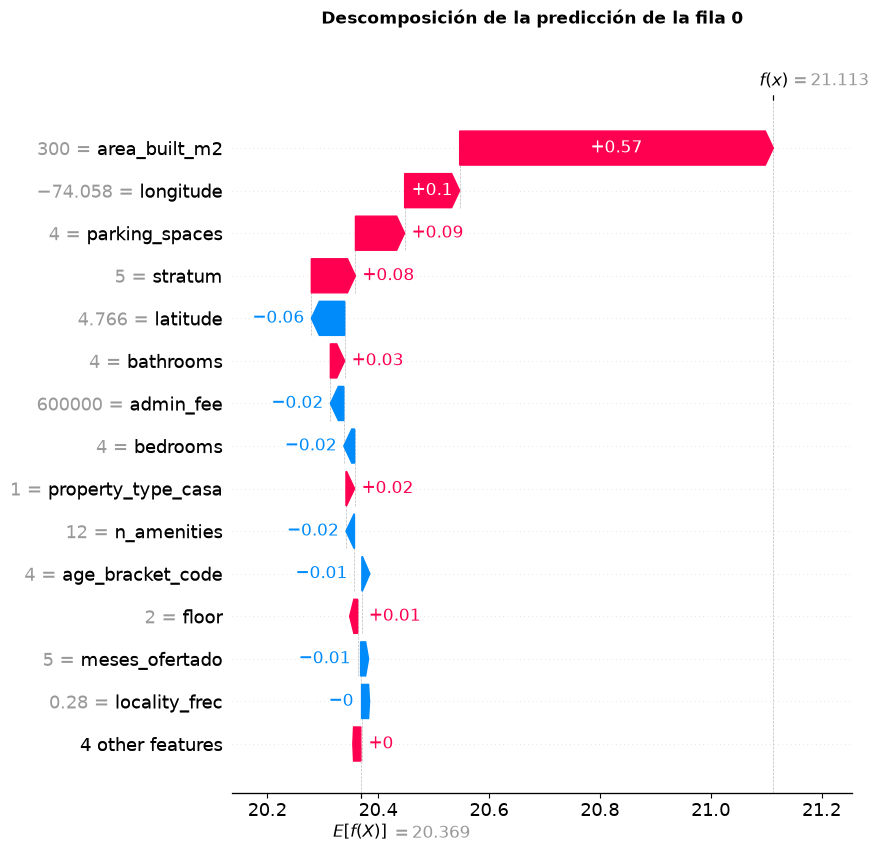

In [334]:
shap_lightgbm = shap_report(cv_lightgbm_results, X_train)

## Seleccionando 6 variables con IM

In [335]:
lightgbm_model_6 = LGBMRegressor(
    n_estimators=600,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    n_jobs=2,
    random_state=42,
    verbose=-1,
)

lightgbm_model_6_pipeline = create_tree_selection_pipeline(
    lightgbm_model_6, n_features_to_select=6
)

In [336]:
cv_lightgbm_6_results = cross_validate_model_cached(
    lightgbm_model_6_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=2,
)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_57a0a1230d5127b559ce08b9cc20a005.pkl


34315

In [337]:
pd.DataFrame(cv_lightgbm_6_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,40.519159,12.580962,-3.632846e+08,-1.897720e+08,-0.185809,0.793172,41.687835,68.585944,-49.393170,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,40.945763,12.561280,-3.444306e+08,-1.760093e+08,-0.170633,0.817086,42.490119,69.367589,-51.242236,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,49.754883,13.593321,-3.788203e+08,-2.095254e+08,-0.204769,0.787828,40.739695,66.629023,-52.484472,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,49.316139,13.238567,-3.769738e+08,-1.853685e+08,-0.183156,0.788856,43.224167,69.480519,-52.964427,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,25.692938,11.185543,-4.070149e+08,-2.053262e+08,-0.222706,0.756852,41.530209,67.588933,-53.726708,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


## Shap Explanation

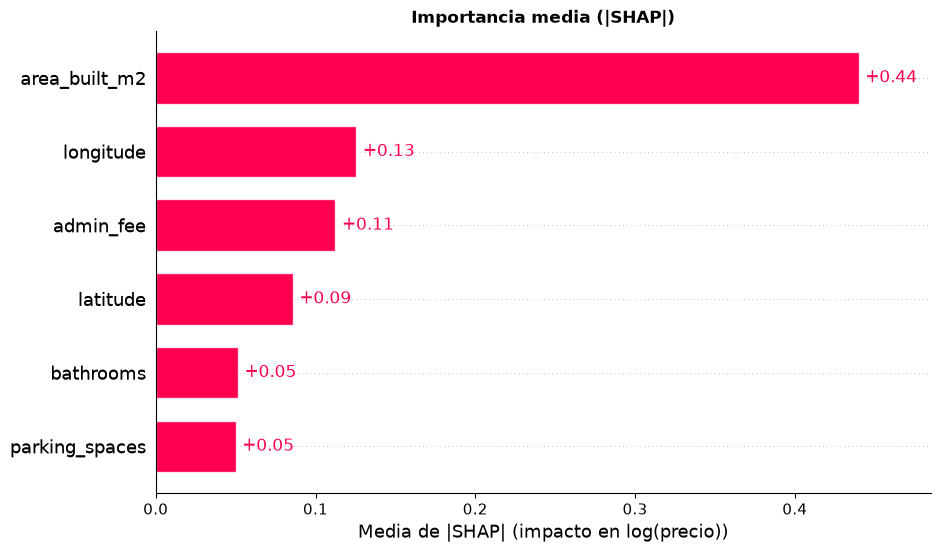

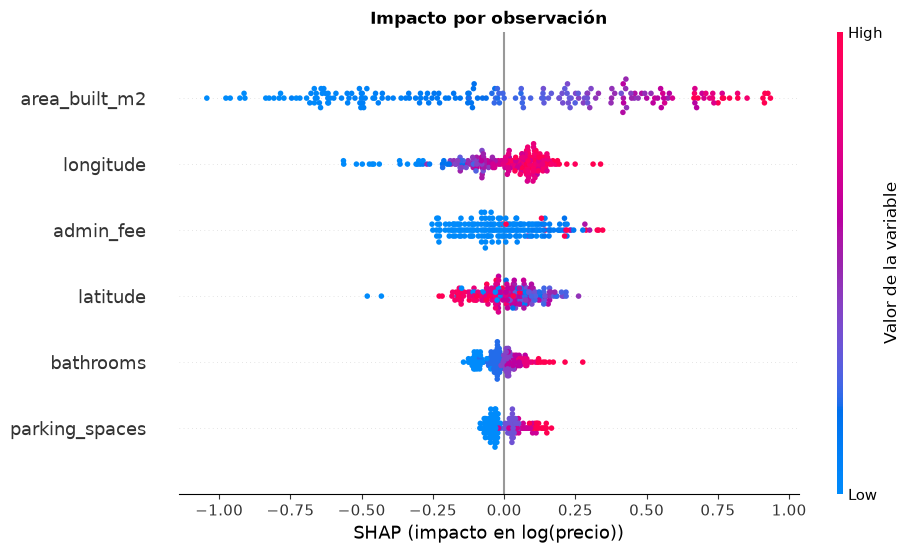

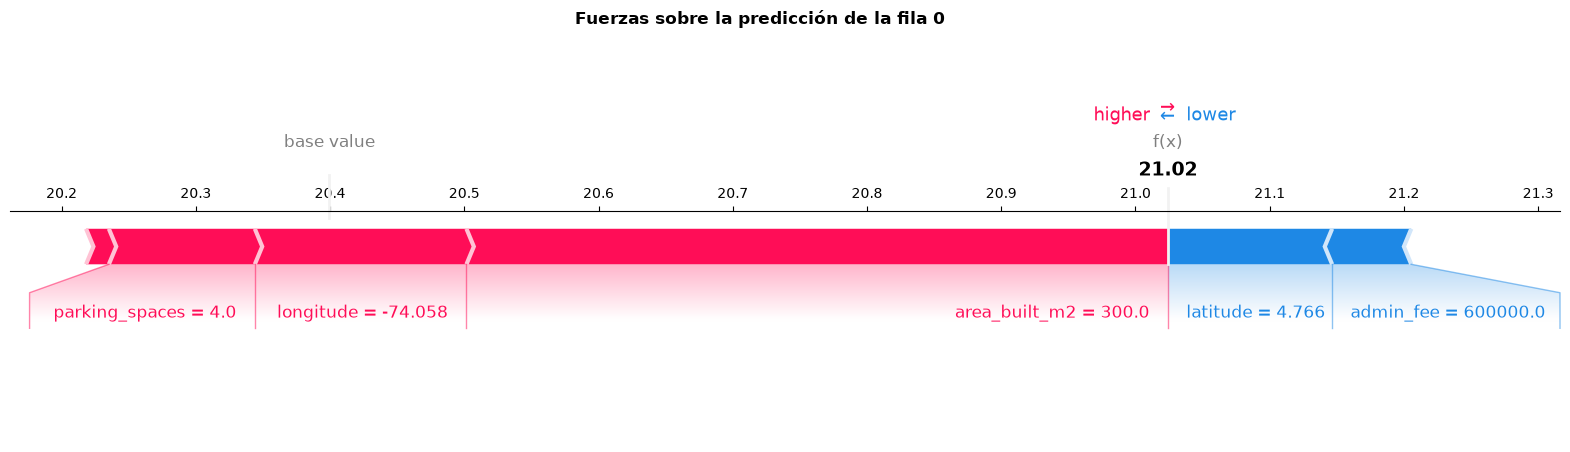

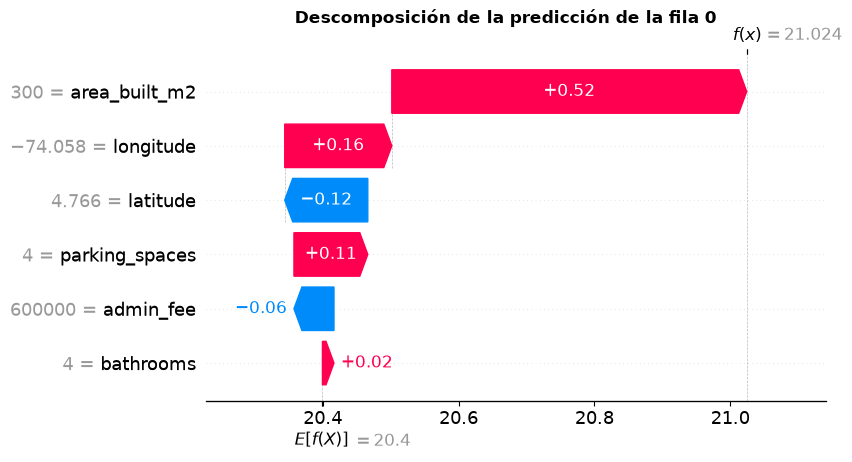

In [338]:
shap_lightgbm_6 = shap_report(cv_lightgbm_6_results, X_train)

# Modelo BART de Cao et al. (2024)
Implementación de BART con corte según los residuos

## Seleccionando 18 variables con IM

In [339]:
art_bart = BARTAtrRegressor(
    trim=True,
    random_state=42,
    num_burnin=3000,
    num_mcmc=6000,
    num_gfr=2,
    keep_every=5,
)

art_bart_pipeline = create_tree_selection_pipeline(
    art_bart, n_features_to_select=18
)

In [340]:
cv_art_bart_results = cross_validate_model_cached(
    art_bart_pipeline,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=2,
)
gc.collect()

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cross_validate_model_cached_1f4ed03a351008ee87264b31d86ce63f.pkl


23506

In [341]:
pd.DataFrame(cv_art_bart_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion,train_indices,test_indices,estimator
0,9264.178893,419.230927,-3.327047e+08,-1.719696e+08,-0.161146,0.826527,41.913633,71.323737,-49.082698,"[1, 2, 4, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17,...","[0, 3, 5, 8, 14, 19, 27, 30, 35, 42, 46, 47, 5...",d:\Externado\Cuarto semestre\bayesiana\proyect...
1,9672.075601,580.535875,-3.334636e+08,-1.702336e+08,-0.159932,0.828549,44.297007,72.106155,-51.129305,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[15, 17, 20, 23, 31, 33, 34, 36, 39, 41, 43, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...
2,9592.499239,474.110733,-3.414360e+08,-1.837838e+08,-0.171107,0.827639,42.603049,71.372106,-52.315076,"[0, 1, 2, 3, 5, 6, 7, 8, 9, 11, 13, 14, 15, 16...","[4, 10, 12, 28, 29, 32, 37, 45, 48, 51, 56, 58...",d:\Externado\Cuarto semestre\bayesiana\proyect...
3,9645.339504,1040.006253,-3.523586e+08,-1.767862e+08,-0.168970,0.815530,43.675889,70.609825,-52.230378,"[0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[2, 18, 24, 25, 26, 44, 49, 52, 53, 62, 66, 67...",d:\Externado\Cuarto semestre\bayesiana\proyect...
4,9008.644279,410.849547,-3.650991e+08,-1.807296e+08,-0.180717,0.804354,42.800678,71.230943,-52.060982,"[0, 2, 3, 4, 5, 8, 10, 12, 14, 15, 17, 18, 19,...","[1, 6, 7, 9, 11, 13, 16, 21, 22, 38, 40, 55, 6...",d:\Externado\Cuarto semestre\bayesiana\proyect...


In [342]:
diagnostico_art_bart = mcmc_diagnostics(cv_art_bart_results, X_train)
diagnostico_art_bart

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\mcmc_diagnostics_c761d491518250380182ee88b8fcf08b.pkl


,chains,draws,sigma2_mean,sigma2_rhat,sigma2_ess_bulk,sigma2_ess_tail,sigma2_mcse_mean,f_rhat_median,f_rhat_max,f_pct_rhat_gt_1_01,f_ess_bulk_median,f_ess_bulk_min
fold,,,,,,,,,,,,
0,2,6000,0.029671,1.466035,3.796829,12.281090,0.000384,1.368908,2.409973,99.971775,4.551634,2.437314
1,2,6000,0.030795,1.419226,4.083969,12.092128,0.000394,1.316434,2.416784,99.943535,5.043139,2.434125
2,2,6000,0.031717,1.464782,3.813748,12.828159,0.000420,1.307651,2.498935,99.858837,5.233462,2.399032
3,2,6000,0.033394,1.506733,3.628630,7.615898,0.000388,1.343914,2.410234,99.887069,4.802425,2.433471
4,2,6000,0.026789,1.291460,5.094452,15.169667,0.000250,1.330133,2.378487,99.887069,4.920545,2.474647


## Traceplot

Sin caché para 'extract_chains' o hubo cambios; calculando...
Resultado guardado en: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\extract_chains_e07d1bfa88feb7e093c14935344e5824.pkl


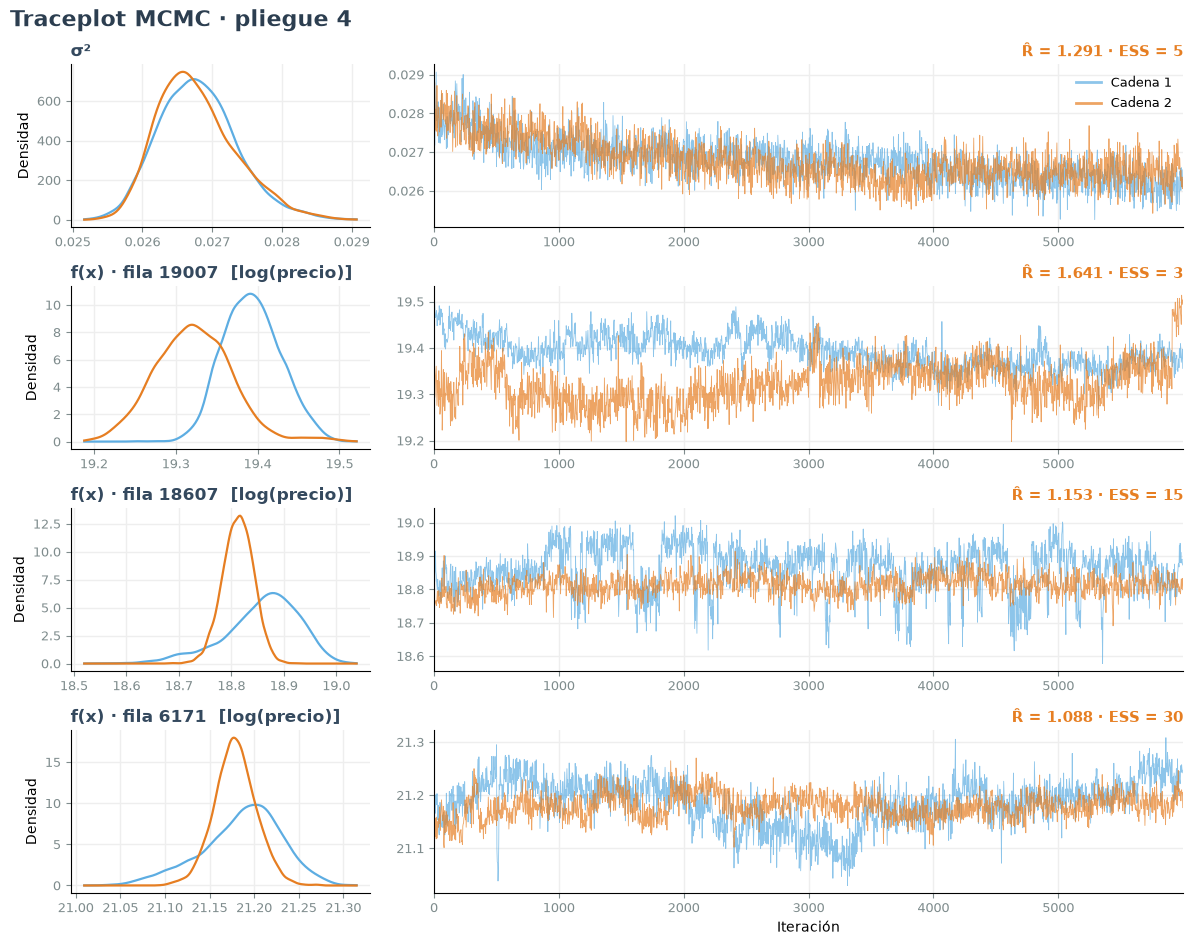

In [343]:
traza_art_bart = extract_chains_cached(cv_art_bart_results, X_train)
traza_art_bart["fig"] = plot_trace(traza_art_bart)

## Shap Explanation

Resultado cargado desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\compute_shap_bf71c7e04e93a21aec6d0b03525353d4.pkl


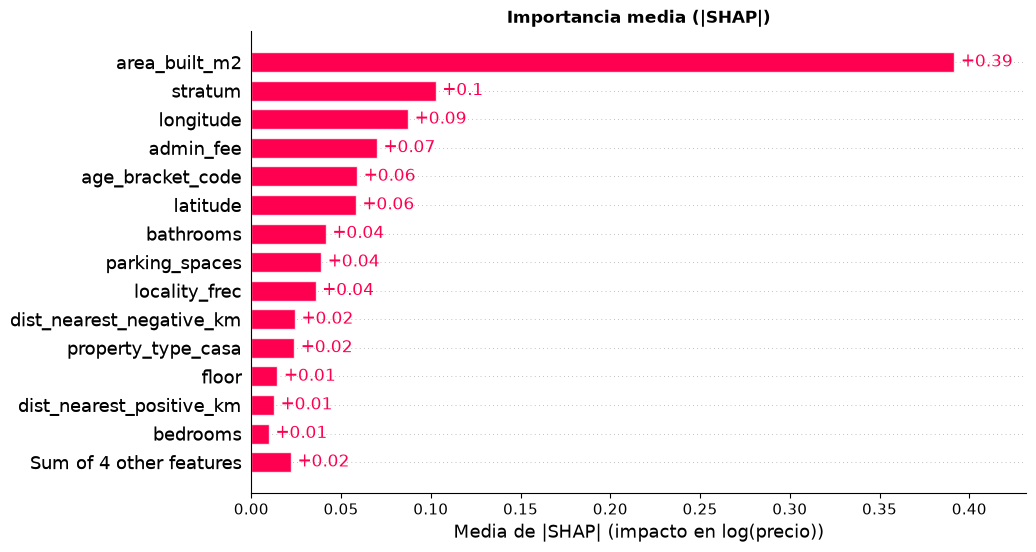

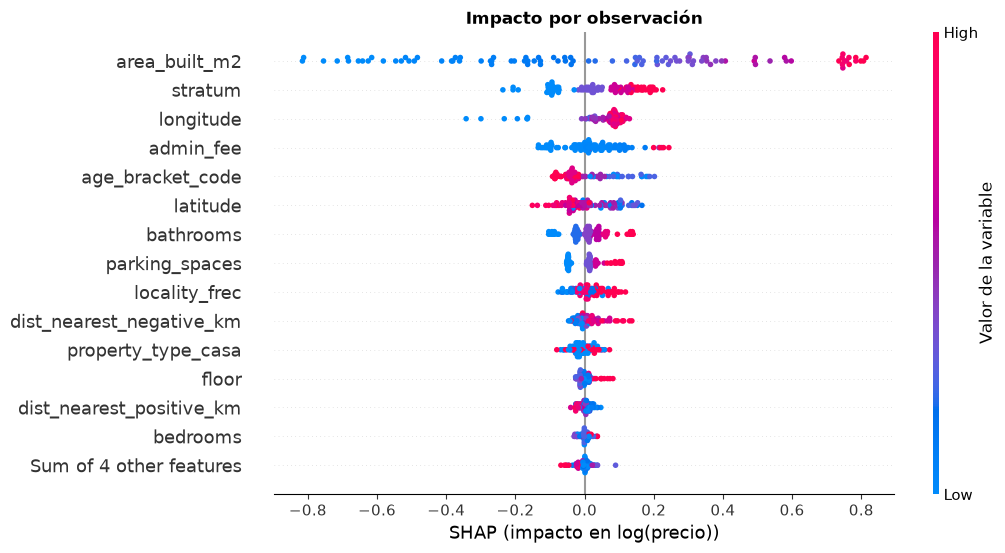

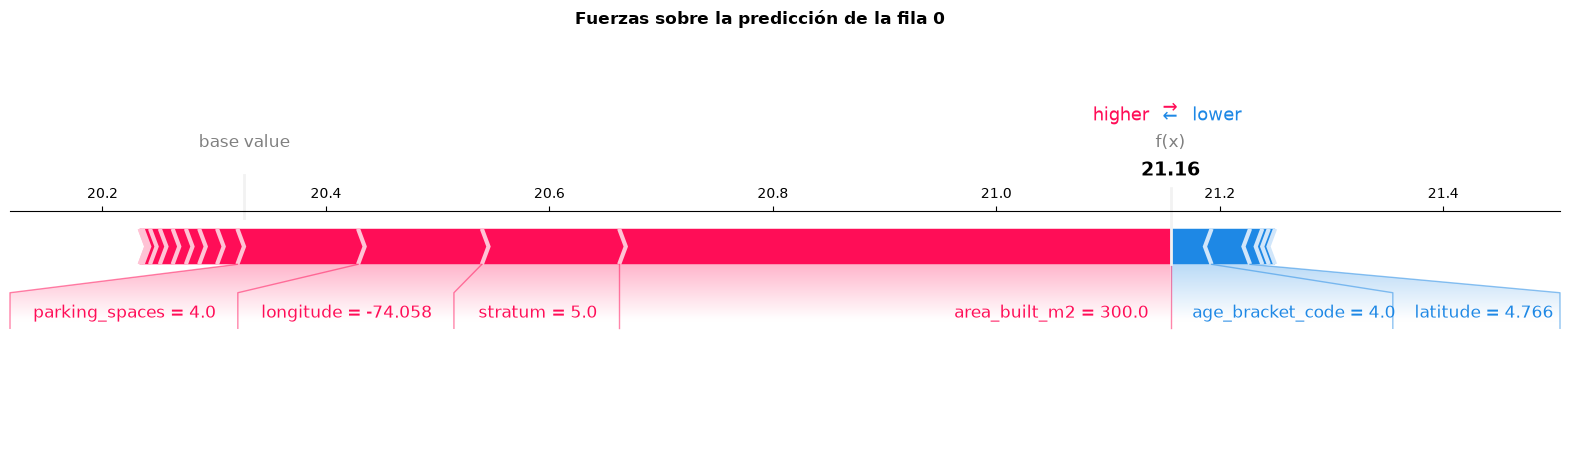

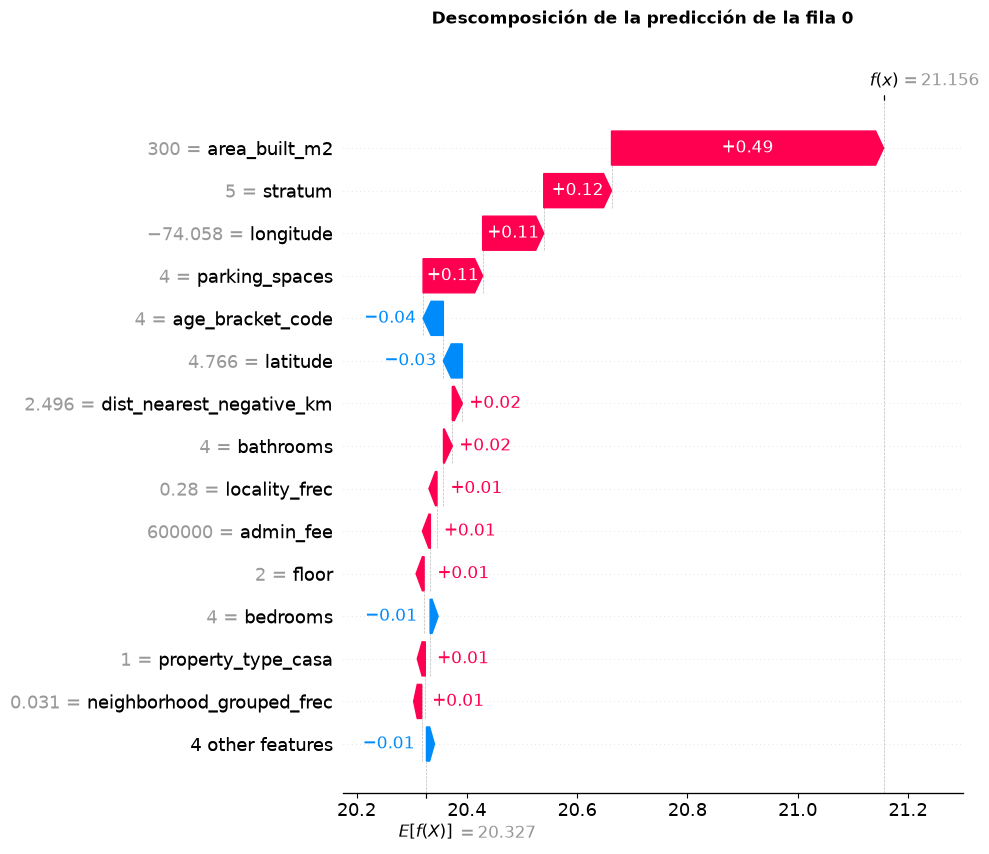

In [344]:
shap_art_bart = compute_shap_cached(
    cv_art_bart_results, X_train, n_explain=100, n_background=50
)
shap_art_bart["figs"] = plot_shap(shap_art_bart["explanation"])

# Comparación de modelos

Métricas de la validación cruzada de 5 *folds* sobre el conjunto de
entrenamiento, media y desviación estándar entre *folds*. RMSE y MAE están en
pesos; MAPE como fracción; `Acc_10`, `Acc_20` y `Sobreprediccion` en %.

In [345]:
summarize_cv(
    {
        "BaseLine (mediana)": cv_results,
        "OLS, 6 variables": ols_cv_results[6],
        "OLS, 18 variables": ols_cv_results[18],
        "BART, 6 variables": cv_classic_bart_6_results,
        "BART, 18 variables": cv_classic_bart_results,
        "Random Forest, 6 variables": cv_random_forest_6_results,
        "Random Forest, 18 variables": cv_random_forest_results,
        "XGBoost, 6 variables": cv_xgboost_6_results,
        "XGBoost, 18 variables": cv_xgboost_results,
        "LightGBM, 6 variables": cv_lightgbm_6_results,
        "LightGBM, 18 variables": cv_lightgbm_results,
        "BART(Atr), 18 variables": cv_art_bart_results,
    }
)

RMSE                         MAE  \
                                    media          desv         media   
BaseLine (mediana)           8.607647e+08  1.535803e+07  5.643709e+08   
OLS, 6 variables             4.501485e+08  2.246608e+07  2.551827e+08   
OLS, 18 variables            4.124241e+08  1.325094e+07  2.245272e+08   
BART, 6 variables            3.997061e+08  2.151621e+07  2.126050e+08   
BART, 18 variables           3.489713e+08  1.124300e+07  1.798479e+08   
Random Forest, 6 variables   3.801722e+08  1.742535e+07  1.977272e+08   
Random Forest, 18 variables  3.567265e+08  1.181869e+07  1.756410e+08   
XGBoost, 6 variables         3.724076e+08  2.013917e+07  1.922138e+08   
XGBoost, 18 variables        3.387921e+08  1.199173e+07  1.659401e+08   
LightGBM, 6 variables        3.741049e+08  2.297378e+07  1.932003e+08   
LightGBM, 18 variables       3.360280e+08  1.206774e+07  1.672331e+08   
BART(Atr), 18 variables      3.450124e+08  1.373943e+07  1.767006e+08   

                                               MAPE                  R2  \
                                     desv     media      desv     media   
BaseLine (mediana)           8.042467e+06  0.724223  0.015425 -0.116856   
OLS, 6 variables             1.060792e+07  0.279484  0.015962  0.694071   
OLS, 18 variables            6.286938e+06  0.217364  0.007514  0.743490   
BART, 6 variables            1.380913e+07  0.215810  0.017004  0.758795   
BART, 18 variables           9.012763e+06  0.172442  0.007279  0.816399   
Random Forest, 6 variables   1.103561e+07  0.202716  0.016197  0.782057   
Random Forest, 18 variables  6.219628e+06  0.170011  0.006960  0.808164   
XGBoost, 6 variables         1.246983e+07  0.193367  0.018417  0.790739   
XGBoost, 18 variables        5.095882e+06  0.157559  0.006317  0.826906   
LightGBM, 6 variables        1.398361e+07  0.193415  0.020427  0.788759   
LightGBM, 18 variables       6.888629e+06  0.158319  0.006192  0.829767   
BART(Atr), 18 variables      5.714384e+06  0.168374  0.008421  0.820520   

                                          Acc_10               Acc_20  \
                                 desv      media      desv      media   
BaseLine (mediana)           0.012625  10.185792  0.627600  19.411706   
OLS, 6 variables             0.027943  28.202806  0.313051  52.436375   
OLS, 18 variables            0.013213  33.549825  0.829033  60.403179   
BART, 6 variables            0.022695  36.203516  0.935628  63.395646   
BART, 18 variables           0.008047  41.985213  0.923689  70.075096   
Random Forest, 6 variables   0.014782  40.195330  0.869744  66.297773   
Random Forest, 18 variables  0.008312  44.751855  0.985296  70.809085   
XGBoost, 6 variables         0.018550  41.539134  1.211629  68.403803   
XGBoost, 18 variables        0.009632  46.389311  1.425788  73.705612   
LightGBM, 6 variables        0.021452  41.934405  0.951815  68.330402   
LightGBM, 18 variables       0.008401  45.864211  1.313817  73.163574   
BART(Atr), 18 variables      0.010458  43.058051  0.935374  71.328553   

                                      Sobreprediccion            
                                 desv           media      desv  
BaseLine (mediana)           0.935391       49.065553  1.228541  
OLS, 6 variables             0.395413       53.644688  1.589333  
OLS, 18 variables            0.632067       53.960884  1.300247  
BART, 6 variables            1.454572       53.029310  1.385786  
BART, 18 variables           0.940773       51.792765  1.059208  
Random Forest, 6 variables   1.088524       53.667317  1.566312  
Random Forest, 18 variables  0.764610       52.854269  1.341974  
XGBoost, 6 variables         1.427077       52.109004  1.718075  
XGBoost, 18 variables        0.678664       51.493525  1.083723  
LightGBM, 6 variables        1.215349       51.962203  1.696244  
LightGBM, 18 variables       0.714789       51.561270  1.012415  
BART(Atr), 18 variables      0.532138       51.363688  1.360180